# QUBO Portfolio Optimisation — Result Analysis

**Experiment:** `grid_final_20260930_002028.csv` (final window, 1,650 runs)  
**Strategies compared:** QUBO (static, buy-and-hold) · QUBO_RB (QUBO with rebalancing, costs & taxes) · MPT (Mean-Variance) · EqualWeight  
**Markets:** India · USA · Europe · Japan · Crypto  
**Parameters swept:** Universe size · Cardinality (B) · Correlation penalty (q) · Lookback window

---


## 1  Imports & Display Settings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ── aesthetics ──────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
PALETTE   = {"QUBO": "#2196F3", "QUBO_RB": "#4CAF50", "MPT": "#FF9800", "EqualWeight": "#9E9E9E"}
LINESTYLES = ["-", "--", "-.", ":"]
MPALETTE  = sns.color_palette("tab10", 5)
MARKETS   = ["India", "USA", "Europe", "Japan", "Crypto"]

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.titlesize": 24,
    "axes.labelsize": 22,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 22,
    "figure.titlesize": 26,
    "figure.titleweight": "bold",
})

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 60)
print("Dependencies loaded ✓")

Dependencies loaded ✓


## 2  Load & Inspect Dataset

In [6]:
CSV_PATH = r"C:\Users\yashg\Desktop\portflio-opti-3.12\results_audited\grid_final_20260930_002028.csv"

raw = pd.read_csv(CSV_PATH)
print(f"Shape : {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print(f"Strategies : {sorted(raw['strategy'].unique())}")
print(f"Markets    : {sorted(raw['market'].unique())}")
print()
raw.head(3)

Shape : 1,650 rows × 86 columns
Strategies : ['EqualWeight', 'MPT', 'QUBO', 'QUBO_RB']
Markets    : ['crypto', 'europe', 'india', 'japan', 'usa']



,strategy,market,universe_size,universe_size_requested,lookback,end_offset,test_start,test_end,n_held,runtime_s,sharpe_ratio,volatility,ann_return,total_return,max_drawdown,sortino,calmar,final_value,oos_n_days,reliability_flag,sharpe_constmix_nocost,exante_expected_return,exante_vol,exante_sharpe,diversification_ratio,metric_basis,universe_label,row_id,status,window,...,garch_mode,use_garch_lambda,div_penalty,garch_legacy_ratio_raw,garch_legacy_clipped,garch_q_mult_raw,garch_q_mult,garch_q_clipped,garch_n_fallback,avg_pairwise_corr,sa_neal_reads,sa_neal_sweeps,sa_neal_seeds,cardinality_ratio,initial_sharpe_constmix_nocost,initial_exante_expected_return,initial_exante_vol,initial_exante_sharpe,initial_diversification_ratio,initial_sortino,initial_calmar,n_rebalances,n_reopt_failures,total_tax_paid,total_tc_paid,cost_drag_pct,liquidation_tax_estimate,bah_liquidation_tax_estimate,max_assets_held,identical_to_bah
0,EqualWeight,india,10,10,126,0,2024-12-27,2025-12-31,10,0.0000,0.3445,0.1371,0.1083,0.1083,-0.0852,0.4958,1.2721,1773314.9096,252,RELIABLE,0.4336,-0.0966,0.1241,-1.3025,2.0294,"NAV (buy-and-hold, entry cost)",u10,final|india|EW|u10|lb126,ok,final,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MPT,india,10,10,126,0,2024-12-27,2025-12-31,5,0.0053,-0.6863,0.1340,-0.0353,-0.0353,-0.1567,-0.9607,-0.2252,1543556.1469,252,RELIABLE,-0.6315,0.2964,0.1510,1.5328,1.5191,"NAV (buy-and-hold, entry cost)",u10,final|india|MPT|u10|q0.3|lb126,ok,final,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,QUBO,india,10,10,126,0,2024-12-27,2025-12-31,2,0.7578,-1.2052,0.1505,-0.1198,-0.1198,-0.2066,-1.6828,-0.5801,1408288.3744,252,RELIABLE,-1.0810,0.3298,0.1724,1.5362,1.3246,"NAV (buy-and-hold, entry cost)",u10,final|india|QUBO|u10|B2|q0.3|lb126,ok,final,...,q_risk,True,0.3000,0.9780,False,1.0225,1.0225,False,0.0000,0.1379,100.0000,1500.0000,3.0000,0.2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
raw.describe(include=[np.number]).T[["count","mean","std","min","50%","max"]].round(4)

,count,mean,std,min,50%,max
universe_size,1650.0000,29.8800,13.9804,10.0000,30.0000,50.0000
universe_size_requested,1650.0000,30.0000,14.1464,10.0000,30.0000,50.0000
lookback,1650.0000,294.0000,157.1973,126.0000,252.0000,504.0000
end_offset,1650.0000,0.0000,0.0000,0.0000,0.0000,0.0000
n_held,1650.0000,9.3891,7.2075,2.0000,8.0000,50.0000
...,...,...,...,...,...,...
total_tc_paid,675.0000,30389.4905,17562.7835,4216.9022,25521.9292,78274.2570
cost_drag_pct,675.0000,7.7901,8.5924,0.6356,4.8067,64.8024
liquidation_tax_estimate,675.0000,67267.7217,59144.7938,0.0000,43537.9165,345088.2786
bah_liquidation_tax_estimate,675.0000,66710.5358,58272.1430,0.0000,56030.7627,382571.7325


In [8]:
# Missing value map
null_counts = raw.isnull().sum()
null_pct    = (null_counts / len(raw) * 100).round(1)
null_df = pd.DataFrame({"missing_count": null_counts, "missing_%": null_pct})
null_df = null_df[null_df["missing_count"] > 0].sort_values("missing_%", ascending=False)
print(f"Columns with any NaN: {len(null_df)}")
null_df

Columns with any NaN: 54


,missing_count,missing_%
effective_positions,1425,86.4000
cost_drag_pct,975,59.1000
liquidation_tax_estimate,975,59.1000
bah_liquidation_tax_estimate,975,59.1000
max_assets_held,975,59.1000
identical_to_bah,975,59.1000
initial_sharpe_constmix_nocost,975,59.1000
initial_exante_expected_return,975,59.1000
initial_exante_vol,975,59.1000
initial_exante_sharpe,975,59.1000


## 3  Data Cleaning & Feature Engineering

In [9]:
df = raw.copy()

# ── universe size: group on the REQUESTED size (10/20/30/40/50) ─────────────
# (the realised size can be 48/49 when a ticker had no data)
df["universe_size_actual"] = df["universe_size"]
df["universe_size"]        = df["universe_size_requested"]

# ── QUBO_RB has no ex-ante block of its own -> use its initial_* values ─────
for tgt, src_col in {"exante_sharpe":          "initial_exante_sharpe",
                     "exante_expected_return": "initial_exante_expected_return",
                     "exante_vol":             "initial_exante_vol",
                     "diversification_ratio":  "initial_diversification_ratio"}.items():
    df[tgt] = df[tgt].fillna(df[src_col])

# ── universe label / strategy ordering ──────────────────────────────────────
ulabel_order = ["u10", "u20", "u30", "u40", "u50"]
df["universe_label"] = pd.Categorical(df["universe_label"], categories=ulabel_order, ordered=True)

strat_order = ["QUBO", "QUBO_RB", "MPT", "EqualWeight"]
df["strategy"] = pd.Categorical(df["strategy"], categories=strat_order, ordered=True)

# ── derived columns ──────────────────────────────────────────────────────────
df["calmar_ratio"]   = df["ann_return"] / df["max_drawdown"].abs().replace(0, np.nan)
df["return_per_vol"] = df["ann_return"] / df["volatility"].replace(0, np.nan)
df["excess_sharpe"]  = df["sharpe_ratio"] - df.groupby("market")["sharpe_ratio"].transform("mean")
# The new CSV has no rfr_adj_ann_return column. Sharpe = excess return / vol,
# so excess (risk-free-adjusted) return ~= Sharpe x Volatility.
df["rfr_adj_ann_return"] = df["sharpe_ratio"] * df["volatility"]

# ── QUBO solver diagnostics (the old diag_* columns no longer exist) ────────
# rebuilt from the solver columns now logged in the CSV
qfam = df["strategy"].isin(["QUBO", "QUBO_RB"])
df["diag_check1_ratio_ok"] = pd.array([pd.NA]*len(df), dtype="boolean")
df["diag_check2_feasible_ok"] = pd.array([pd.NA]*len(df), dtype="boolean")
df["diag_check3_card_ok"] = pd.array([pd.NA]*len(df), dtype="boolean")
df.loc[qfam, "diag_check1_ratio_ok"]    = (df.loc[qfam, "lambda_over_max_marginal"] >= 1.0).values   # lambda >= max marginal gain
df.loc[qfam, "diag_check2_feasible_ok"] = (df.loc[qfam, "neal_feasible_fraction"]   >= 1.0).values   # every SA read feasible
df.loc[qfam, "diag_check3_card_ok"]     = ((df.loc[qfam, "final_count"] == df.loc[qfam, "B"]) &
                                           (df.loc[qfam, "cardinality_violated"] == 0)).values      # exactly B assets
df["diag_all_ok"] = (df["diag_check1_ratio_ok"] & df["diag_check2_feasible_ok"] & df["diag_check3_card_ok"])

qubo_mask = df["strategy"] == "QUBO"
df["diag_ok_str"] = "N/A"
df.loc[qfam, "diag_ok_str"] = df.loc[qfam, "diag_all_ok"].map({True: "PASS", False: "FAIL"})

print("Cleaning complete.")
print(f"  Rows             : {len(df):,}")
print(f"  QUBO rows        : {qubo_mask.sum():,}")
print(f"  QUBO diag pass   : {df.loc[qubo_mask,'diag_all_ok'].sum()} / {qubo_mask.sum()}")
df.dtypes.value_counts()


Cleaning complete.
  Rows             : 1,650
  QUBO rows        : 675
  QUBO diag pass   : 675 / 675


float64     61
str         17
int64        8
object       4
boolean      4
category     1
category     1
Name: count, dtype: int64

In [50]:
# ── Drop EqualWeight and QUBO_RB from the analysis ──────────────────────────
DROP_STRATS = ["EqualWeight", "QUBO_RB"]

df = df[~df["strategy"].isin(DROP_STRATS)].copy()

# redefine the ordering everything downstream relies on
strat_order = ["QUBO", "MPT"]
df["strategy"] = pd.Categorical(df["strategy"].astype(str),
                                categories=strat_order, ordered=True)

# keep derived subsets in sync
qubo_mask = df["strategy"] == "QUBO"

print(f"Remaining rows : {len(df):,}")
print(df["strategy"].value_counts().to_string())

Remaining rows : 900
strategy
QUBO    675
MPT     225


## 4  Strategy Performance Summary

Key metrics aggregated by strategy across all markets and parameter configurations.


In [51]:
PERF_METRICS = ["sharpe_ratio","ann_return","rfr_adj_ann_return",
                "volatility","max_drawdown","diversification_ratio",
                "exante_sharpe","calmar_ratio"]

summary = (df.groupby("strategy")[PERF_METRICS]
             .agg(["mean","median","std"])
             .round(4))
summary

sharpe_ratio               ann_return                \
                 mean median    std       mean median    std   
strategy                                                       
QUBO           0.4749 0.4834 0.5286     0.1473 0.1208 0.1706   
MPT            0.4810 0.5122 0.5341     0.1444 0.1181 0.1816   

         rfr_adj_ann_return               volatility                \
                       mean median    std       mean median    std   
strategy                                                             
QUBO                 0.1444 0.1211 0.1584     0.2858 0.2357 0.1248   
MPT                  0.1439 0.1510 0.1566     0.2998 0.2521 0.1238   

         max_drawdown                diversification_ratio                \
                 mean  median    std                  mean median    std   
strategy                                                                   
QUBO          -0.2347 -0.2301 0.0684                1.5220 1.5236 0.1354   
MPT           -0.2483 -0.2401 0.0785                1.4992 1.4914 0.1128   

         exante_sharpe               calmar_ratio                
                  mean median    std         mean median    std  
strategy                                                         
QUBO            2.2870 2.3591 0.9138       0.7106 0.5297 0.7468  
MPT             2.2959 2.4031 0.8916       0.6966 0.6562 0.7543

In [52]:
MARKET_RENAME = {
    "india":  "India",
    "europe": "Europe",
    "usa":    "USA",
    "japan":  "Japan",
    "crypto": "Crypto",
}

df["market"] = df["market"].replace(MARKET_RENAME)
MARKETS = [MARKET_RENAME.get(m, m) for m in MARKETS]

print(df["market"].unique())

<ArrowStringArray>
['India', 'USA', 'Europe', 'Japan', 'Crypto']
Length: 5, dtype: str


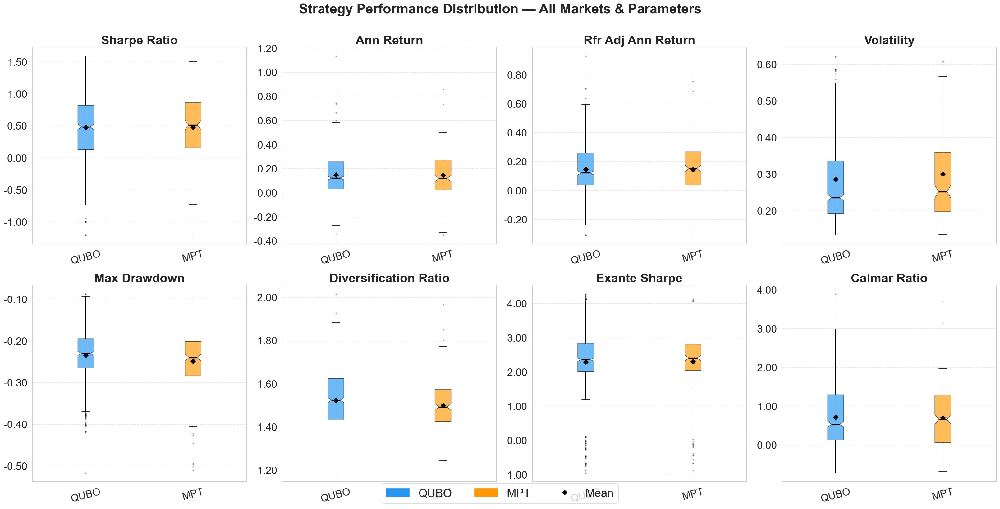

In [53]:
fig, axes = plt.subplots(2, 4, figsize=(27, 13.5))
axes = axes.flatten()

for ax, metric in zip(axes, PERF_METRICS):
    data   = [df[df["strategy"] == s][metric].dropna() for s in strat_order]
    colors = [PALETTE[s] for s in strat_order]
    bp     = ax.boxplot(data, patch_artist=True, notch=True,
                        medianprops=dict(color="black", linewidth=2),
                        whiskerprops=dict(linewidth=1.2),
                        flierprops=dict(marker=".", markersize=3, alpha=0.4))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color); patch.set_alpha(0.65)

    # overlay means
    means = [d.mean() for d in data]
    ax.scatter(range(1, len(strat_order)+1), means, color="black",
               marker="D", s=45, zorder=5, label="Mean")

    ax.set_xticks(range(1, len(strat_order)+1))
    ax.set_xticklabels(strat_order, rotation=15)
    ax.set_title(metric.replace("_", " ").title())
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

# shared legend
legend_handles = [Patch(color=PALETTE[s], label=s) for s in strat_order]
legend_handles.append(Line2D([0],[0], marker="D", color="black", markersize=7, label="Mean", linestyle="None"))
fig.legend(handles=legend_handles, loc="lower center", ncol=4, fontsize=22, frameon=True)

fig.suptitle("Strategy Performance Distribution — All Markets & Parameters", fontsize=26, y=1.01)
plt.tight_layout()
plt.show()

## 5  Market-wise Performance Analysis

In [54]:
market_summary = (df.groupby(["market","strategy"])
                    [["sharpe_ratio","ann_return","volatility","max_drawdown","rfr_adj_ann_return"]]
                    .mean().round(4).unstack("strategy"))
market_summary

sharpe_ratio        ann_return        volatility        max_drawdown  \
strategy         QUBO    MPT       QUBO    MPT       QUBO    MPT         QUBO   
market                                                                          
Crypto         0.4555 0.2365     0.1290 0.0026     0.5119 0.5126      -0.3259   
Europe         0.4005 0.4038     0.1116 0.1177     0.2228 0.2292      -0.2441   
India          0.0789 0.0820     0.0707 0.0702     0.1664 0.1719      -0.1578   
Japan          0.5124 0.7683     0.1274 0.2168     0.2857 0.3146      -0.2248   
USA            0.9273 0.9143     0.2976 0.3146     0.2421 0.2707      -0.2211   

                 rfr_adj_ann_return         
strategy     MPT               QUBO    MPT  
market                                      
Crypto   -0.3612             0.2325 0.1142  
Europe   -0.2491             0.0861 0.0925  
India    -0.1640             0.0137 0.0137  
Japan    -0.2238             0.1566 0.2440  
USA      -0.2433             0.2331 0.2548

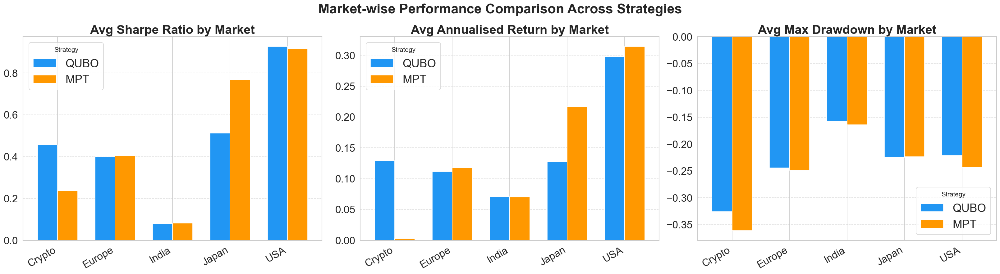

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(27, 7.5))
metrics_show = ["sharpe_ratio", "ann_return", "max_drawdown"]
titles       = ["Sharpe Ratio", "Annualised Return", "Max Drawdown"]

for ax, metric, title in zip(axes, metrics_show, titles):
    mkt_data = df.groupby(["market","strategy"])[metric].mean().unstack("strategy")[strat_order]
    mkt_data.plot(kind="bar", ax=ax, color=[PALETTE[s] for s in strat_order],
                  edgecolor="white", width=0.7)
    ax.set_title(f"Avg {title} by Market")
    ax.set_xlabel("")
    ax.set_xticklabels(mkt_data.index, rotation=30, ha="right")
    ax.legend(title="Strategy", fontsize=22)
    ax.grid(True, axis="y", linestyle="--", alpha=0.6)

fig.suptitle("Market-wise Performance Comparison Across Strategies", fontsize=26)
plt.tight_layout()
plt.show()

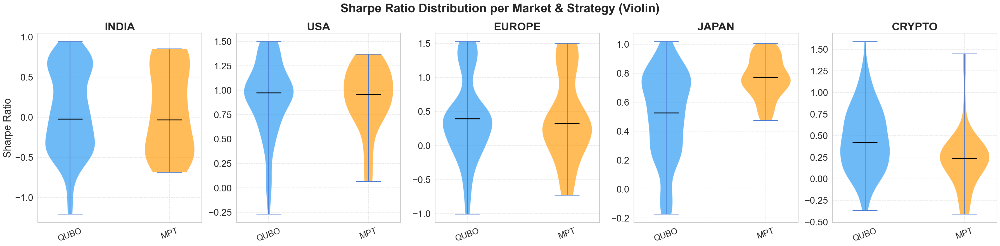

In [56]:
# Sharpe ratio violin per market
fig, axes = plt.subplots(1, 5, figsize=(30, 7.5), sharey=False)

for ax, market in zip(axes, MARKETS):
    sub = df[df["market"] == market]
    data   = [sub[sub["strategy"] == s]["sharpe_ratio"].dropna() for s in strat_order]
    colors = [PALETTE[s] for s in strat_order]
    parts  = ax.violinplot(data, positions=range(len(strat_order)),
                           showmedians=True, showmeans=False)
    for pc, color in zip(parts["bodies"], colors):
        pc.set_facecolor(color); pc.set_alpha(0.65)
    parts["cmedians"].set_color("black"); parts["cmedians"].set_linewidth(2)
    ax.set_title(market.upper())
    ax.set_xticks(range(len(strat_order)))
    ax.set_xticklabels(strat_order, rotation=20, fontsize=18)
    ax.set_ylabel("Sharpe Ratio" if ax == axes[0] else "")
    ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Sharpe Ratio Distribution per Market & Strategy (Violin)", fontsize=26)
plt.tight_layout()
plt.show()

## 6  Risk-Return Landscape & Pareto Frontier

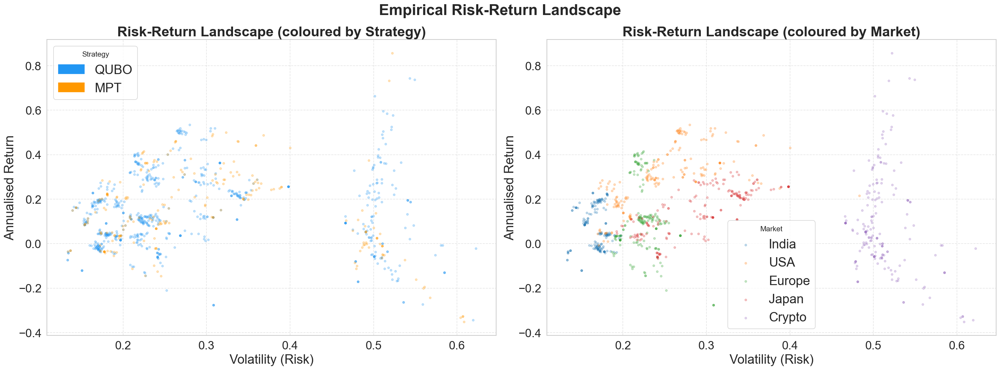

In [57]:
# Filter outliers for cleaner plot (vol < 1.5, |ann_return| < 1.0)
plot_df = df[(df["volatility"] < 1.5) & (df["ann_return"].abs() < 1.0)].copy()

fig, axes = plt.subplots(1, 2, figsize=(24, 9))

# ── LEFT: coloured by strategy ───────────────────────────────────────────────
ax = axes[0]
for strat in strat_order:
    sub = plot_df[plot_df["strategy"] == strat]
    ax.scatter(sub["volatility"], sub["ann_return"],
               color=PALETTE[strat], alpha=0.25, s=12, label=strat)
handles = [Patch(color=PALETTE[s], label=s) for s in strat_order]
ax.legend(handles=handles, title="Strategy", fontsize=22)
ax.set_xlabel("Volatility (Risk)"); ax.set_ylabel("Annualised Return")
ax.set_title("Risk-Return Landscape (coloured by Strategy)")
ax.grid(True, linestyle="--", alpha=0.5)

# ── RIGHT: coloured by market ────────────────────────────────────────────────
ax = axes[1]
mkt_colors = dict(zip(MARKETS, MPALETTE))
for mkt in MARKETS:
    sub = plot_df[plot_df["market"] == mkt]
    ax.scatter(sub["volatility"], sub["ann_return"],
               color=mkt_colors[mkt], alpha=0.25, s=12, label=mkt)
ax.legend(title="Market", fontsize=22)
ax.set_xlabel("Volatility (Risk)"); ax.set_ylabel("Annualised Return")
ax.set_title("Risk-Return Landscape (coloured by Market)")
ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Empirical Risk-Return Landscape", fontsize=26)
plt.tight_layout()
plt.show()

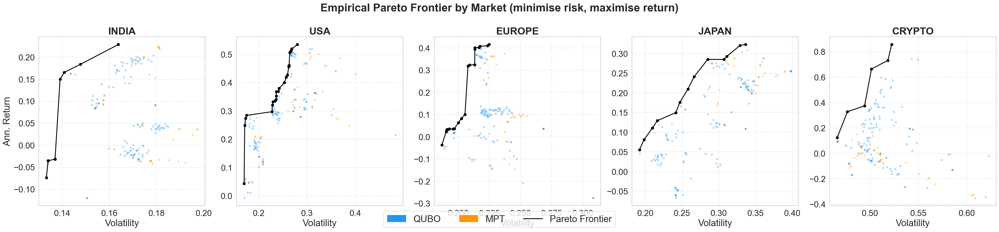

In [58]:
def pareto_front(df_in, x_col="volatility", y_col="ann_return"):
    """Return rows on the Pareto frontier (minimise x, maximise y)."""
    pts = df_in[[x_col, y_col]].dropna().values
    idx = df_in[[x_col, y_col]].dropna().index
    pareto_idx = []
    for i, (xi, yi) in enumerate(pts):
        dominated = any(
            (pts[j, 0] <= xi) and (pts[j, 1] >= yi) and
            ((pts[j, 0] < xi) or (pts[j, 1] > yi))
            for j in range(len(pts)) if j != i
        )
        if not dominated:
            pareto_idx.append(idx[i])
    return df_in.loc[pareto_idx].sort_values(x_col)

fig, axes = plt.subplots(1, 5, figsize=(33, 7.5), sharey=False)

for ax, market in zip(axes, MARKETS):
    sub = plot_df[plot_df["market"] == market].copy()
    pf  = pareto_front(sub)

    for strat in strat_order:
        s = sub[sub["strategy"] == strat]
        ax.scatter(s["volatility"], s["ann_return"],
                   color=PALETTE[strat], alpha=0.3, s=14)

    ax.plot(pf["volatility"], pf["ann_return"],
            color="black", linewidth=2, zorder=5, label="Pareto")
    ax.scatter(pf["volatility"], pf["ann_return"],
               color="black", s=35, zorder=6)

    ax.set_title(market.upper()); ax.set_xlabel("Volatility")
    ax.set_ylabel("Ann. Return" if ax == axes[0] else "")
    ax.grid(True, linestyle="--", alpha=0.5)

legend_h  = [Patch(color=PALETTE[s], label=s) for s in strat_order]
legend_h += [Line2D([0],[0], color="black", linewidth=2, label="Pareto Frontier")]
fig.legend(handles=legend_h, loc="lower center", ncol=4, fontsize=22, frameon=True)
fig.suptitle("Empirical Pareto Frontier by Market (minimise risk, maximise return)", fontsize=26, y=1.01)
plt.tight_layout()
plt.show()

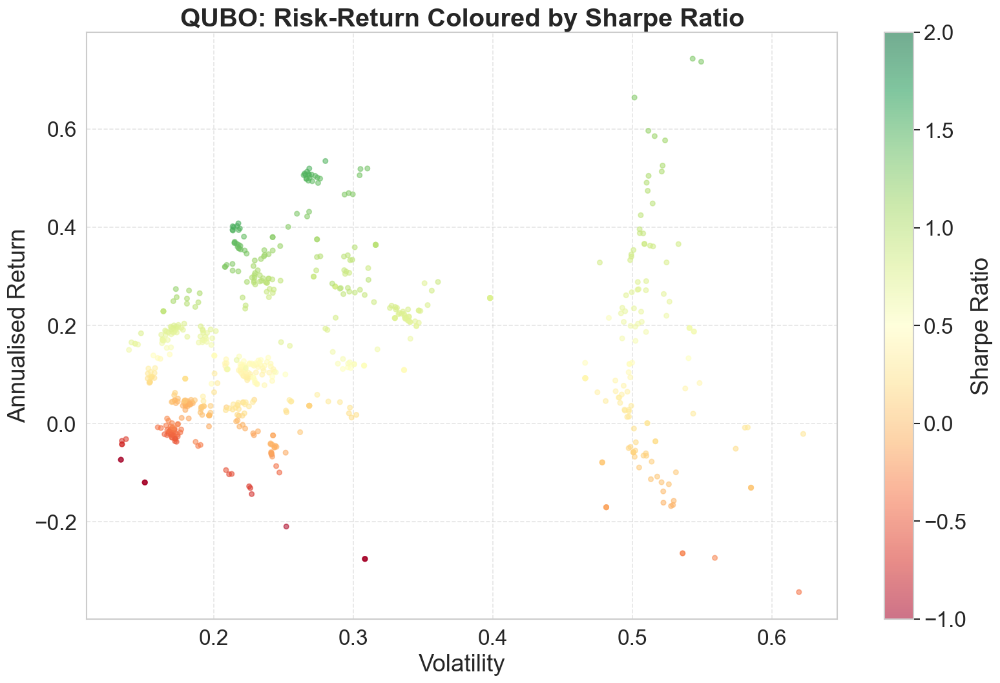

In [59]:
# Sharpe-coloured scatter
sc_df = plot_df[plot_df["strategy"] == "QUBO"].copy()

fig, ax = plt.subplots(figsize=(13.5, 9))
sc = ax.scatter(sc_df["volatility"], sc_df["ann_return"],
                c=sc_df["sharpe_ratio"], cmap="RdYlGn",
                alpha=0.55, s=20, vmin=-1, vmax=2)
plt.colorbar(sc, ax=ax, label="Sharpe Ratio")
ax.set_xlabel("Volatility"); ax.set_ylabel("Annualised Return")
ax.set_title("QUBO: Risk-Return Coloured by Sharpe Ratio")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 7  Parameter Sensitivity Analysis

### 7.1  Cardinality (B) — number of selected assets


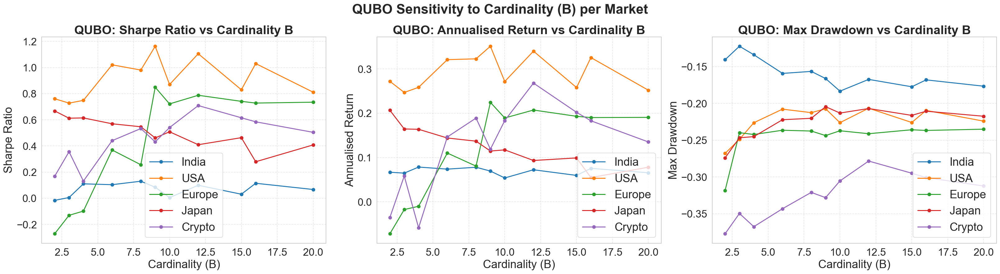

In [60]:
qubo_df = df[df["strategy"] == "QUBO"].copy()

fig, axes = plt.subplots(1, 3, figsize=(27, 7.5))
metrics = ["sharpe_ratio", "ann_return", "max_drawdown"]
titles  = ["Sharpe Ratio", "Annualised Return", "Max Drawdown"]

for ax, metric, title in zip(axes, metrics, titles):
    for mkt, color in zip(MARKETS, MPALETTE):
        sub = qubo_df[qubo_df["market"] == mkt]
        grp = sub.groupby("B")[metric].mean()
        ax.plot(grp.index, grp.values, marker="o", label=mkt, color=color, linewidth=1.8)
    ax.set_xlabel("Cardinality (B)"); ax.set_ylabel(title)
    ax.set_title(f"QUBO: {title} vs Cardinality B")
    ax.legend(fontsize=22); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("QUBO Sensitivity to Cardinality (B) per Market", fontsize=26)
plt.tight_layout()
plt.show()

### 7.2  Correlation Penalty (q)

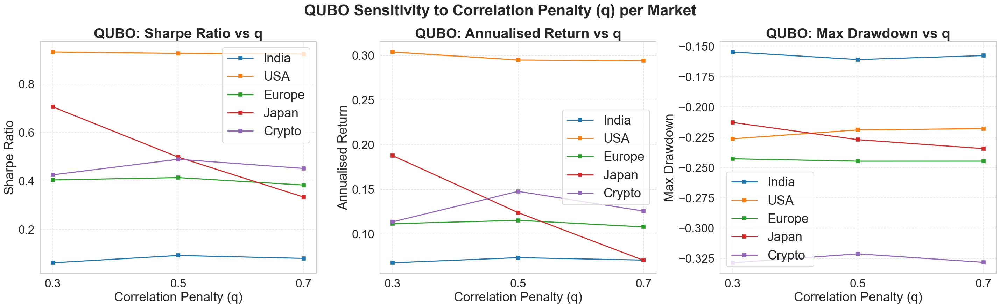

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))

for ax, metric, title in zip(axes, metrics, titles):
    grp = qubo_df.groupby(["q","market"])[metric].mean().unstack("market")[MARKETS]
    for mkt, color in zip(MARKETS, MPALETTE):
        ax.plot(grp.index, grp[mkt].values, marker="s",
                label=mkt, color=color, linewidth=1.8)
    ax.set_xlabel("Correlation Penalty (q)"); ax.set_ylabel(title)
    ax.set_title(f"QUBO: {title} vs q")
    ax.legend(fontsize=22); ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_xticks([0.3, 0.5, 0.7])

fig.suptitle("QUBO Sensitivity to Correlation Penalty (q) per Market", fontsize=26)
plt.tight_layout()
plt.show()

### 7.3  Lookback Window

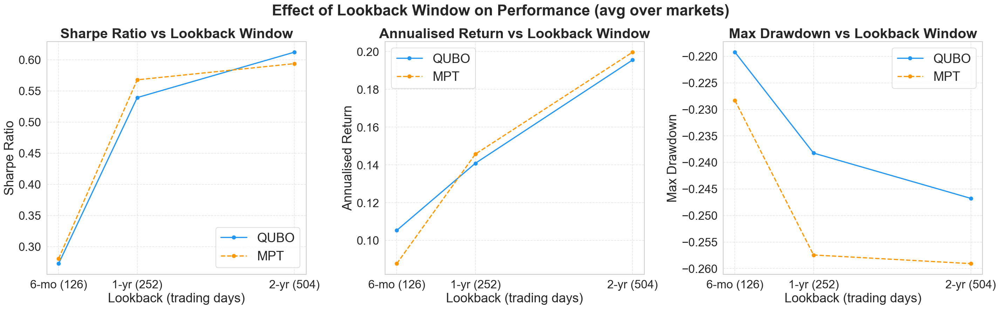

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))

for ax, metric, title in zip(axes, metrics, titles):
    for strat, linestyle in zip(strat_order, LINESTYLES):
        grp = df[df["strategy"]==strat].groupby(["lookback","market"])[metric].mean().unstack("market")
        mean_across_markets = grp.mean(axis=1)
        ax.plot(mean_across_markets.index, mean_across_markets.values,
                marker="o", linestyle=linestyle, label=strat,
                color=PALETTE[strat], linewidth=2)
    ax.set_xlabel("Lookback (trading days)"); ax.set_ylabel(title)
    ax.set_title(f"{title} vs Lookback Window")
    ax.set_xticks([126, 252, 504])
    ax.set_xticklabels(["6-mo (126)", "1-yr (252)", "2-yr (504)"])
    ax.legend(fontsize=22); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Effect of Lookback Window on Performance (avg over markets)", fontsize=26)
plt.tight_layout()
plt.show()

### 7.4  Sharpe Sensitivity Heat-map: B × q (QUBO per market)

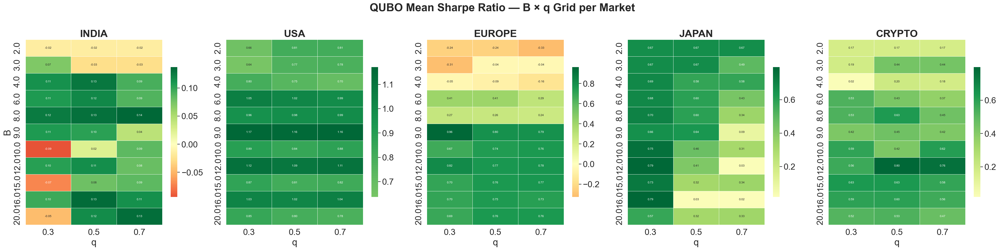

In [63]:
fig, axes = plt.subplots(1, 5, figsize=(33, 8))

for ax, market in zip(axes, MARKETS):
    sub   = qubo_df[qubo_df["market"] == market]
    pivot = sub.groupby(["B","q"])["sharpe_ratio"].mean().unstack("q")
    sns.heatmap(pivot, ax=ax, annot=True, fmt=".2f",
                cmap="RdYlGn", center=0, linewidths=0.3,
                cbar_kws={"shrink": 0.7}, annot_kws={"size": 7})
    ax.set_title(market.upper())
    ax.set_xlabel("q"); ax.set_ylabel("B" if ax == axes[0] else "")

fig.suptitle("QUBO Mean Sharpe Ratio — B × q Grid per Market", fontsize=26, y=1.02)
plt.tight_layout()
plt.show()

## 8  Universe Size Scaling Analysis

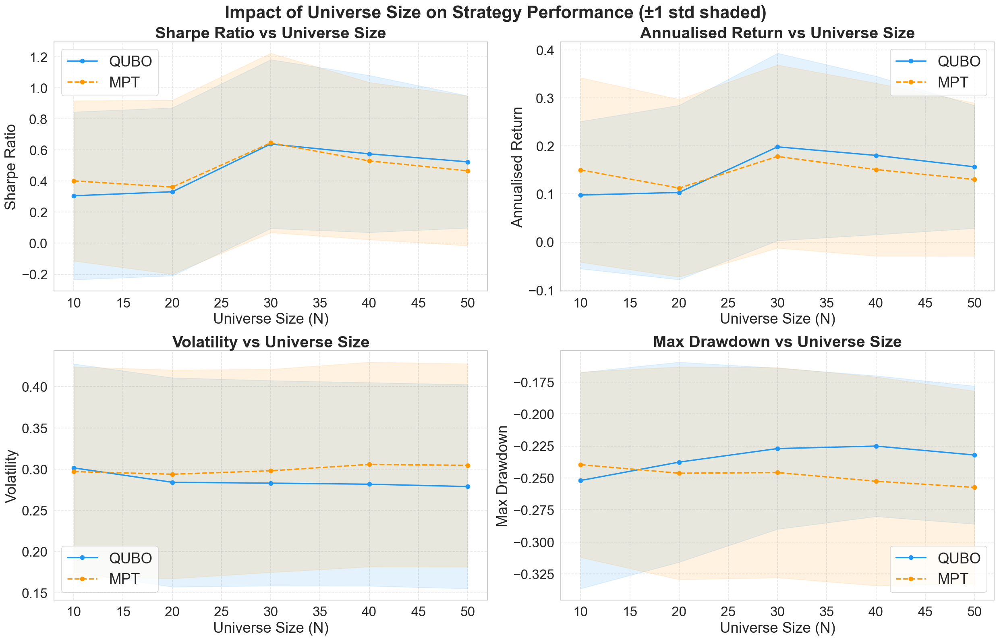

In [64]:
fig, axes = plt.subplots(2, 2, figsize=(21, 13.5))
u_metrics = ["sharpe_ratio","ann_return","volatility","max_drawdown"]
u_titles  = ["Sharpe Ratio","Annualised Return","Volatility","Max Drawdown"]

for ax, metric, title in zip(axes.flatten(), u_metrics, u_titles):
    for strat, linestyle in zip(strat_order, LINESTYLES):
        sub = df[df["strategy"]==strat]
        grp = sub.groupby("universe_size")[metric].agg(["mean","std"])
        ax.plot(grp.index, grp["mean"], marker="o", linestyle=linestyle,
                color=PALETTE[strat], label=strat, linewidth=2)
        ax.fill_between(grp.index,
                        grp["mean"] - grp["std"],
                        grp["mean"] + grp["std"],
                        color=PALETTE[strat], alpha=0.12)
    ax.set_xlabel("Universe Size (N)"); ax.set_ylabel(title)
    ax.set_title(f"{title} vs Universe Size")
    ax.legend(fontsize=22); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Impact of Universe Size on Strategy Performance (±1 std shaded)", fontsize=26)
plt.tight_layout()
plt.show()

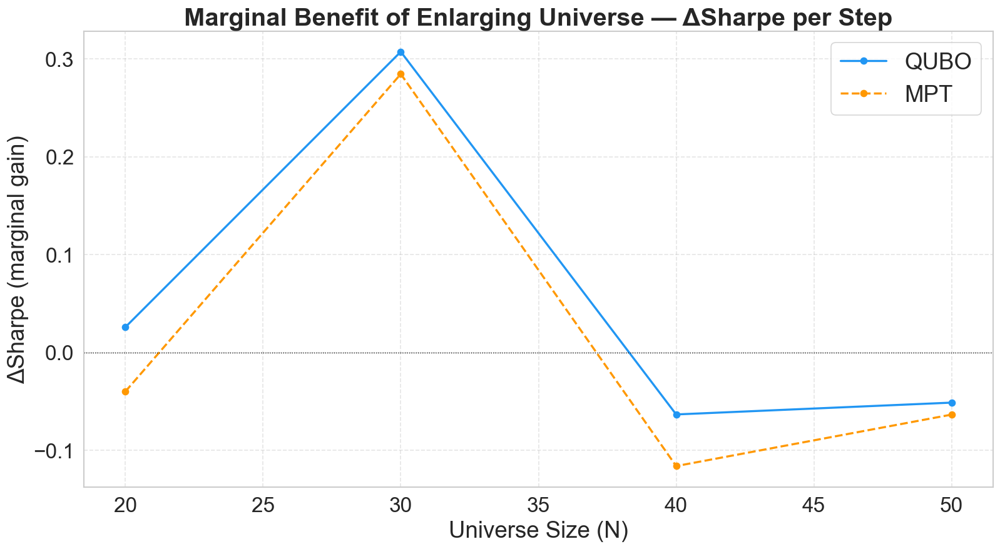

In [65]:
# Marginal gain in Sharpe as N grows
fig, ax = plt.subplots(figsize=(13.5, 7.5))

for strat, linestyle in zip(strat_order, LINESTYLES):
    sub  = df[df["strategy"]==strat].groupby("universe_size")["sharpe_ratio"].mean()
    delta = sub.diff()
    ax.plot(delta.index, delta.values, marker="o", linestyle=linestyle,
            color=PALETTE[strat], label=strat, linewidth=2)

ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xlabel("Universe Size (N)"); ax.set_ylabel("ΔSharpe (marginal gain)")
ax.set_title("Marginal Benefit of Enlarging Universe — ΔSharpe per Step")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

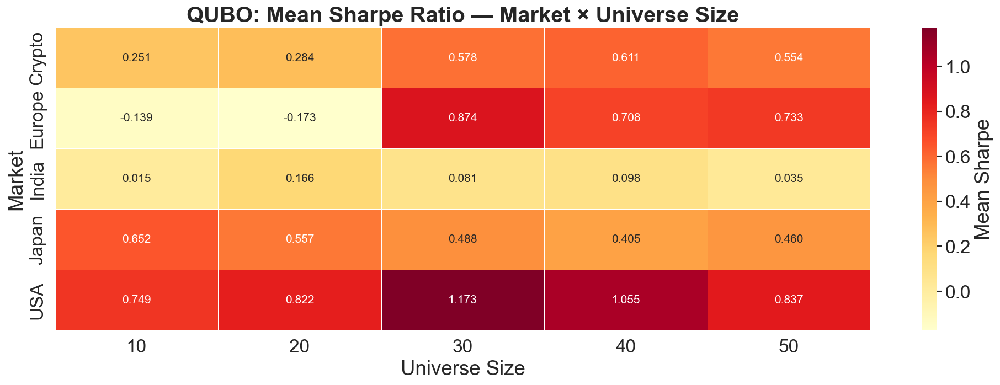

In [66]:
# Per-market universe-size heatmap for QUBO
pivot_u = (qubo_df.groupby(["market","universe_size"])["sharpe_ratio"]
           .mean().unstack("universe_size").round(3))
fig, ax = plt.subplots(figsize=(16.5, 6))
sns.heatmap(pivot_u, ax=ax, annot=True, fmt=".3f", cmap="YlOrRd",
            linewidths=0.4, cbar_kws={"label": "Mean Sharpe"})
ax.set_title("QUBO: Mean Sharpe Ratio — Market × Universe Size")
ax.set_xlabel("Universe Size"); ax.set_ylabel("Market")
plt.tight_layout()
plt.show()

## 9  QUBO Solver Diagnostics

The new CSV logs solver internals directly, so the pass/fail checks are rebuilt from them:
- **Check 1** — λ calibration: `lambda_over_max_marginal ≥ 1` (penalty dominates the largest marginal gain)
- **Check 2** — SA feasibility: `neal_feasible_fraction = 1` (every annealing read satisfied the cardinality constraint)
- **Check 3** — Cardinality: `final_count == B` and `cardinality_violated == 0`

`diag_all_ok` is `True` only when all three checks pass.



In [67]:
# Overall pass rate
diag_counts = qubo_df["diag_all_ok"].value_counts()
print("QUBO diagnostic pass/fail counts:")
print(diag_counts)
print(f"\nPass rate: {diag_counts.get(True,0)/len(qubo_df)*100:.1f}%")

QUBO diagnostic pass/fail counts:
diag_all_ok
True    675
Name: count, dtype: Int64

Pass rate: 100.0%


In [68]:
# Pass rate per market
pr = (qubo_df.groupby("market")["diag_all_ok"]
      .agg(["sum","count"])
      .rename(columns={"sum":"pass","count":"total"}))
pr["pass_rate_%"] = (pr["pass"]/pr["total"]*100).round(1)
print("Diagnostic pass rate per market:")
pr

Diagnostic pass rate per market:


,pass,total,pass_rate_%
market,,,
Crypto,135,135,100.0000
Europe,135,135,100.0000
India,135,135,100.0000
Japan,135,135,100.0000
USA,135,135,100.0000


All 675 QUBO runs pass every diagnostic check (no FAIL group to compare).


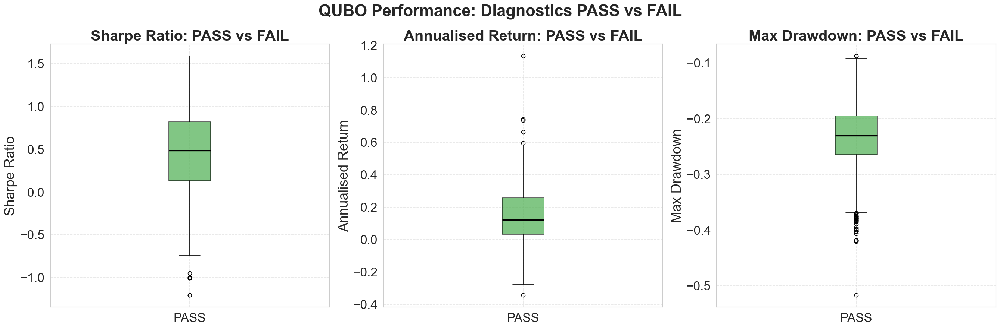

In [69]:
# Performance: PASS vs FAIL
fig, axes = plt.subplots(1, 3, figsize=(22.5, 7.5))

for ax, metric, title in zip(axes, ["sharpe_ratio","ann_return","max_drawdown"],
                              ["Sharpe Ratio","Annualised Return","Max Drawdown"]):
    data_pass = qubo_df[qubo_df["diag_all_ok"]==True][metric].dropna()
    data_fail = qubo_df[qubo_df["diag_all_ok"]==False][metric].dropna()
    groups = [("PASS", data_pass, "#4CAF50")]
    if len(data_fail):
        groups.append(("FAIL", data_fail, "#F44336"))
    bp = ax.boxplot([g[1] for g in groups], patch_artist=True,
                    medianprops=dict(color="black", linewidth=2))
    for box, (_, _, col) in zip(bp["boxes"], groups):
        box.set_facecolor(col); box.set_alpha(0.7)
    ax.set_xticks(range(1, len(groups)+1)); ax.set_xticklabels([g[0] for g in groups])
    ax.set_title(f"{title}: PASS vs FAIL"); ax.set_ylabel(title)
    ax.grid(True, linestyle="--", alpha=0.5)

n_fail = int((qubo_df["diag_all_ok"]==False).sum())
if n_fail == 0:
    print(f"All {len(qubo_df)} QUBO runs pass every diagnostic check (no FAIL group to compare).")
fig.suptitle("QUBO Performance: Diagnostics PASS vs FAIL", fontsize=26)
plt.tight_layout()
plt.show()


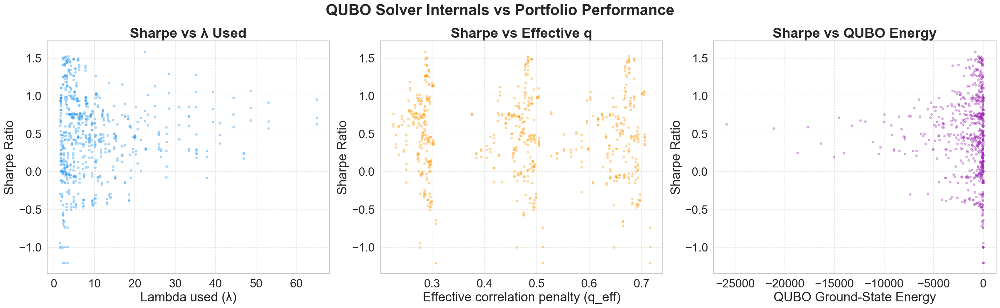

In [70]:
# Lambda calibration analysis
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))

ax = axes[0]
ax.scatter(qubo_df["lambda_used"], qubo_df["sharpe_ratio"],
           alpha=0.3, s=12, color="#2196F3")
ax.set_xlabel("Lambda used (λ)"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Sharpe vs λ Used")
ax.grid(True, linestyle="--", alpha=0.5)

ax = axes[1]
ax.scatter(qubo_df["q_eff"], qubo_df["sharpe_ratio"],
           alpha=0.3, s=12, color="#FF9800")
ax.set_xlabel("Effective correlation penalty (q_eff)"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Sharpe vs Effective q")
ax.grid(True, linestyle="--", alpha=0.5)

ax = axes[2]
ax.scatter(qubo_df["qubo_energy"], qubo_df["sharpe_ratio"],
           alpha=0.3, s=12, color="#9C27B0")
ax.set_xlabel("QUBO Ground-State Energy"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Sharpe vs QUBO Energy")
ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("QUBO Solver Internals vs Portfolio Performance", fontsize=26)
plt.tight_layout()
plt.show()


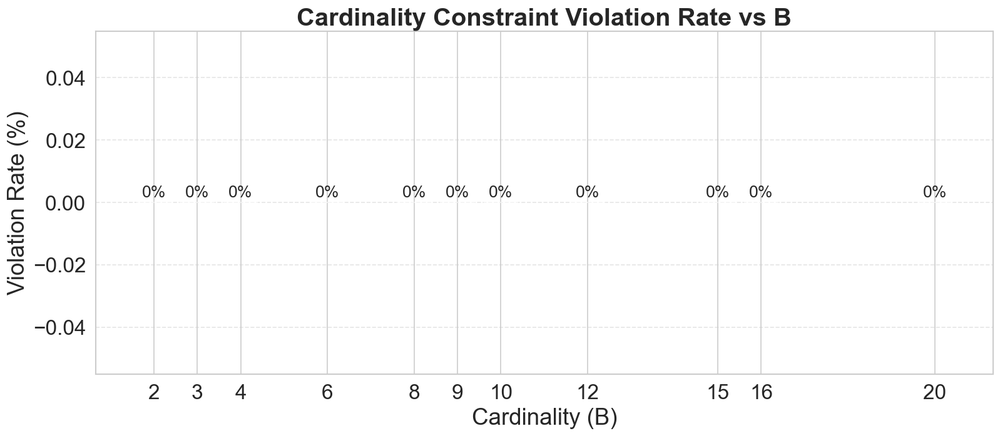

In [71]:
# Cardinality violation rate per B value
viol_rate = (qubo_df.groupby("B")["cardinality_violated"]
             .mean().mul(100).round(1))
fig, ax = plt.subplots(figsize=(13.5, 6))
bars = ax.bar(viol_rate.index, viol_rate.values,
              color="#F44336", alpha=0.7, edgecolor="white")
ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=16)
ax.set_xlabel("Cardinality (B)"); ax.set_ylabel("Violation Rate (%)")
ax.set_title("Cardinality Constraint Violation Rate vs B")
ax.set_xticks(viol_rate.index)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 10  Portfolio Concentration Analysis

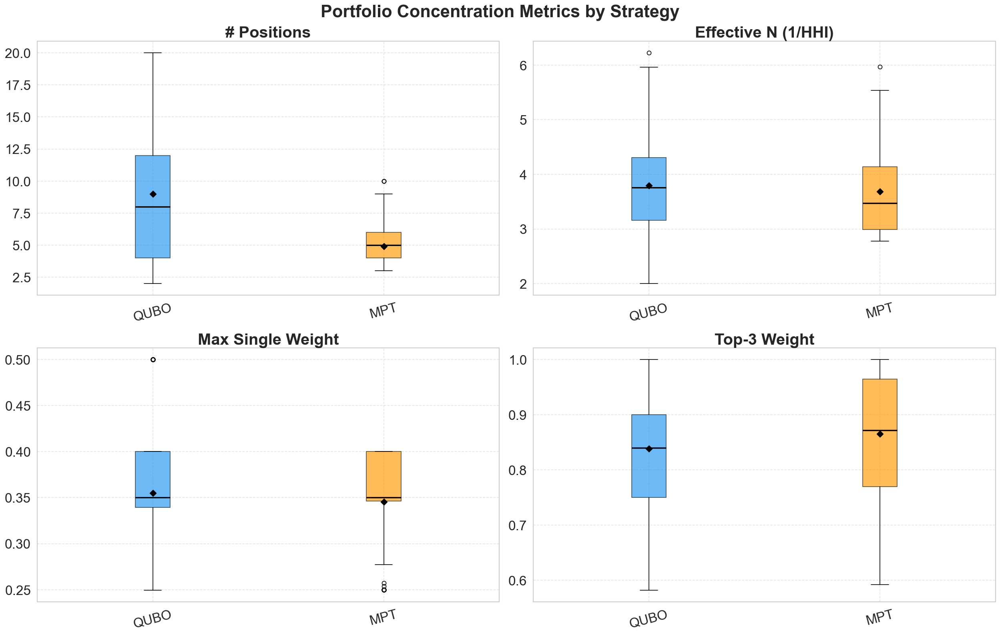

In [72]:
conc_metrics = ["conc_n_positions","conc_effective_n",
                "conc_max_weight","conc_top3_weight"]
conc_titles  = ["# Positions","Effective N (1/HHI)",
                "Max Single Weight","Top-3 Weight"]

fig, axes = plt.subplots(2, 2, figsize=(21, 13.5))

for ax, metric, title in zip(axes.flatten(), conc_metrics, conc_titles):
    data   = [df[df["strategy"]==s][metric].dropna() for s in strat_order]
    colors = [PALETTE[s] for s in strat_order]
    bp = ax.boxplot(data, patch_artist=True, notch=False,
                    medianprops=dict(color="black", linewidth=2))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color); patch.set_alpha(0.65)
    means = [d.mean() for d in data]
    ax.scatter(range(1, len(strat_order)+1), means,
               color="black", marker="D", s=45, zorder=5)
    ax.set_xticks(range(1, len(strat_order)+1))
    ax.set_xticklabels(strat_order, rotation=15)
    ax.set_title(title); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Portfolio Concentration Metrics by Strategy", fontsize=26)
plt.tight_layout()
plt.show()

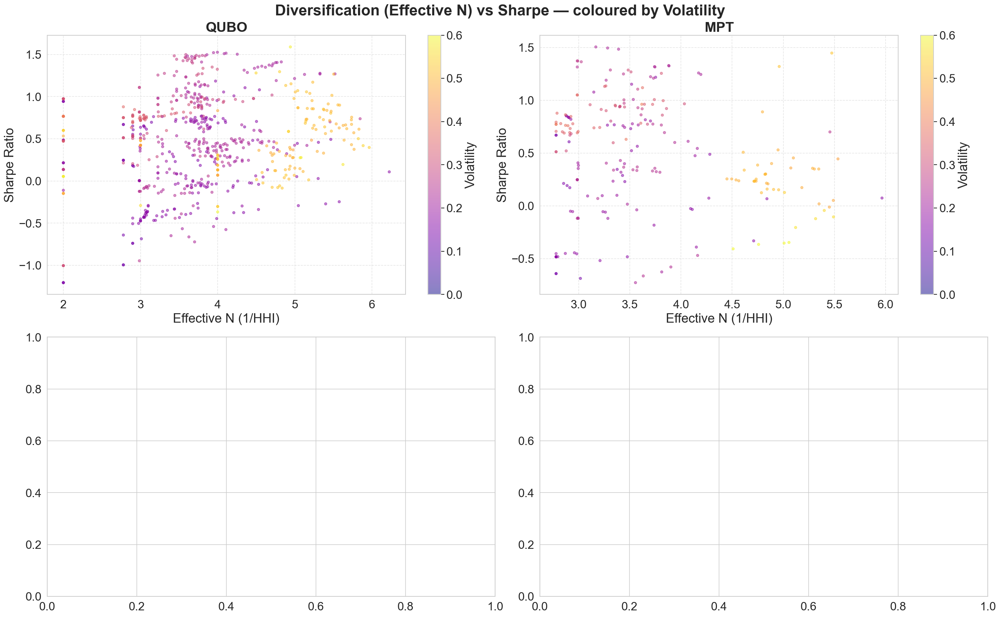

In [73]:
# Concentration vs performance scatter
fig, axes = plt.subplots(2, 2, figsize=(24, 15))

for ax, strat in zip(axes.flatten(), strat_order):
    sub = df[df["strategy"]==strat].dropna(subset=["conc_effective_n","sharpe_ratio"])
    sc  = ax.scatter(sub["conc_effective_n"], sub["sharpe_ratio"],
                     c=sub["volatility"], cmap="plasma",
                     alpha=0.5, s=18, vmin=0, vmax=0.6)
    plt.colorbar(sc, ax=ax, label="Volatility")
    ax.set_xlabel("Effective N (1/HHI)")
    ax.set_ylabel("Sharpe Ratio")
    ax.set_title(strat)
    ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Diversification (Effective N) vs Sharpe — coloured by Volatility", fontsize=26)
plt.tight_layout()
plt.show()


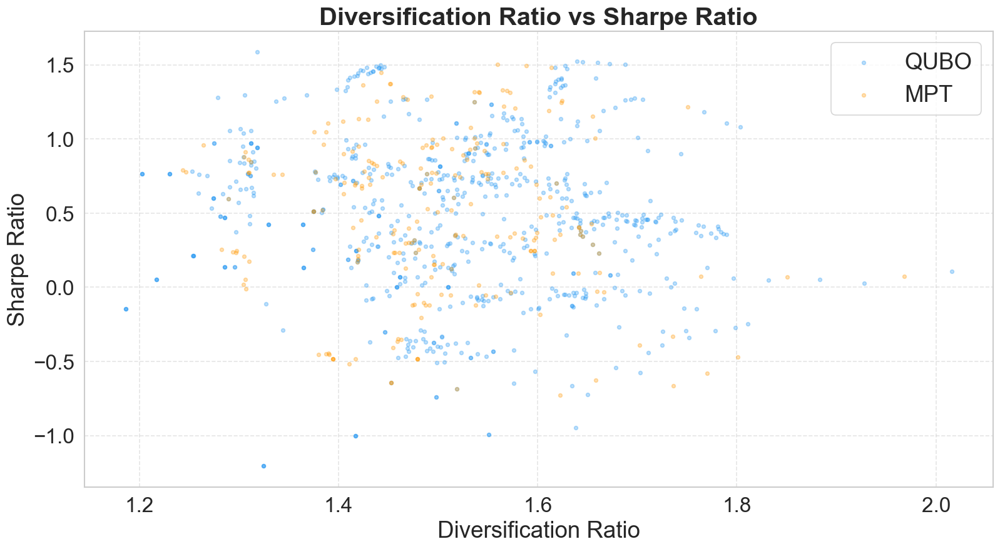

In [74]:
# Diversification ratio vs Sharpe per strategy
fig, ax = plt.subplots(figsize=(13.5, 7.5))
for strat in strat_order:
    sub = df[df["strategy"]==strat].dropna(subset=["diversification_ratio","sharpe_ratio"])
    ax.scatter(sub["diversification_ratio"], sub["sharpe_ratio"],
               color=PALETTE[strat], alpha=0.3, s=12, label=strat)

ax.set_xlabel("Diversification Ratio"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Diversification Ratio vs Sharpe Ratio")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 11  Inter-Metric Correlation Analysis

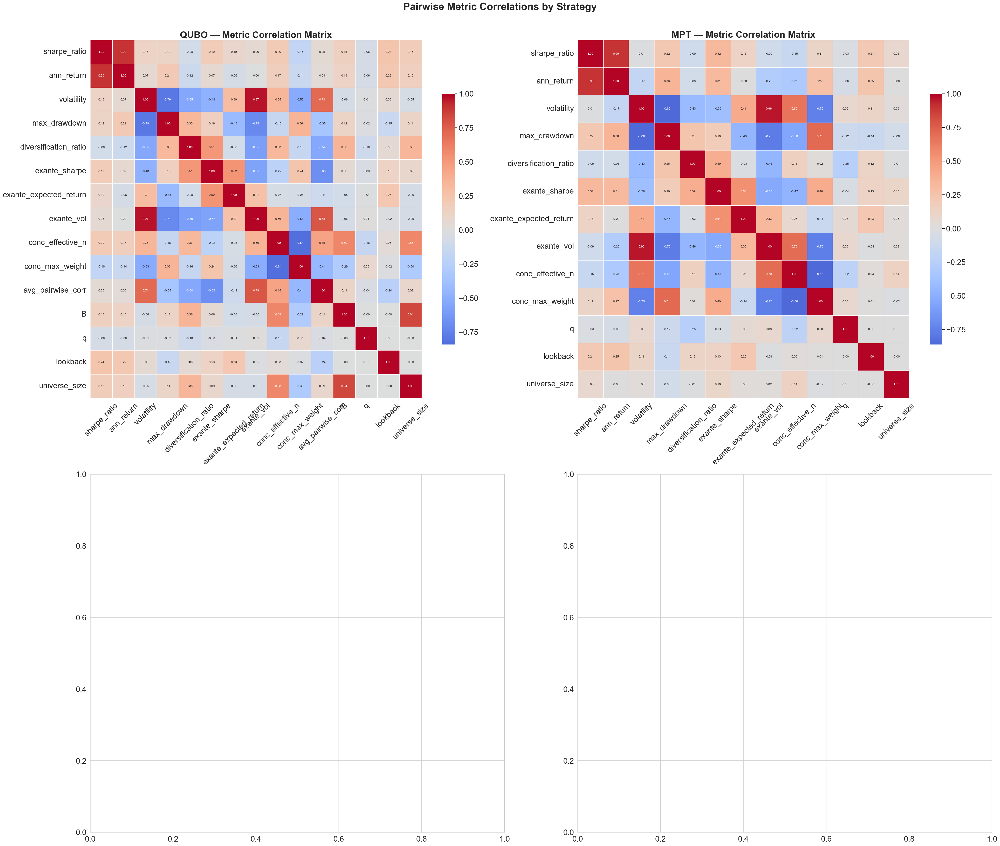

In [75]:
corr_cols = ["sharpe_ratio","ann_return","volatility","max_drawdown",
             "diversification_ratio","exante_sharpe","exante_expected_return",
             "exante_vol","conc_effective_n","conc_max_weight",
             "avg_pairwise_corr","B","q","lookback","universe_size"]

fig, axes = plt.subplots(2, 2, figsize=(36, 30))

for ax, strat in zip(axes.flatten(), strat_order):
    sub  = df[df["strategy"]==strat][corr_cols].dropna(how="all")
    sub  = sub.loc[:, sub.nunique() > 1]          # drop constant / all-NaN columns
    corr = sub.corr().round(2)
    sns.heatmap(corr, ax=ax, mask=False, annot=True, fmt=".2f",
                cmap="coolwarm", center=0, linewidths=0.3,
                annot_kws={"size": 8}, cbar_kws={"shrink": 0.7})
    ax.set_title(f"{strat} — Metric Correlation Matrix")
    ax.tick_params(axis="x", rotation=45, labelsize=20)
    ax.tick_params(axis="y", rotation=0,  labelsize=20)

fig.suptitle("Pairwise Metric Correlations by Strategy", fontsize=26, y=1.01)
plt.tight_layout()
plt.show()


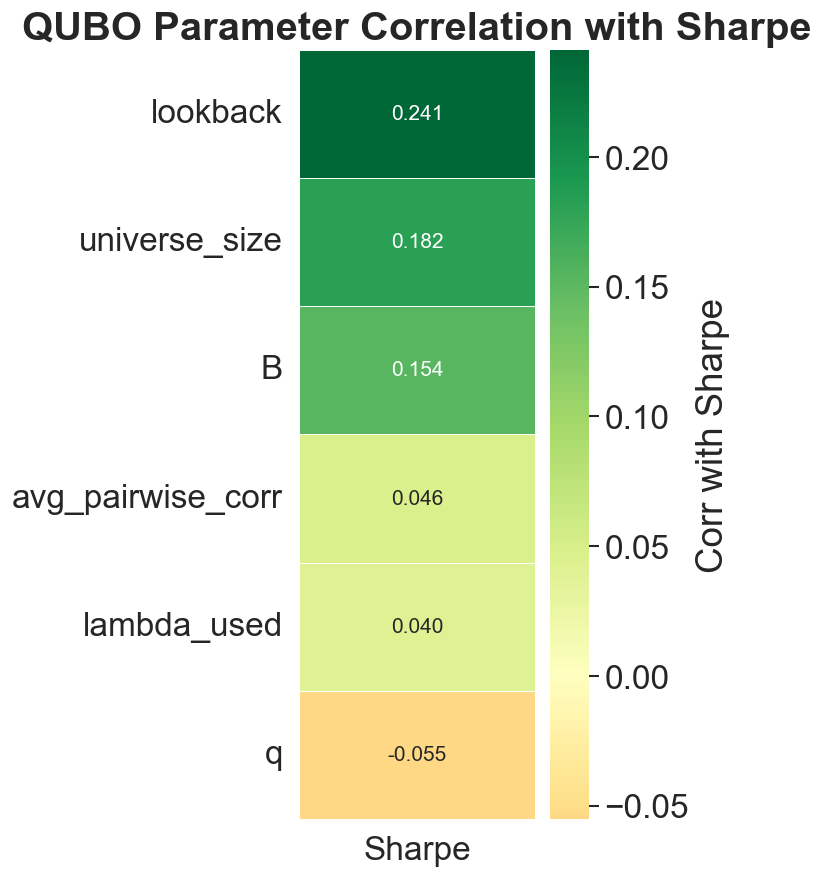

In [76]:
# Parameter impact heatmap (avg Sharpe) - QUBO only
param_cols = ["B", "q", "lookback", "universe_size",
              "avg_pairwise_corr", "lambda_used"]
perf_col   = "sharpe_ratio"

sub  = qubo_df[param_cols + [perf_col]].dropna()
corr = sub.corr()[[perf_col]].drop(perf_col).sort_values(perf_col, ascending=False)

fig, ax = plt.subplots(figsize=(6, 7.5))
sns.heatmap(corr, ax=ax, annot=True, fmt=".3f", cmap="RdYlGn",
            center=0, linewidths=0.5, cbar_kws={"label": "Corr with Sharpe"})
ax.set_title("QUBO Parameter Correlation with Sharpe")
ax.set_ylabel(""); ax.set_xticklabels(["Sharpe"])
plt.tight_layout()
plt.show()

## 17  General Pareto Frontier (All Markets)

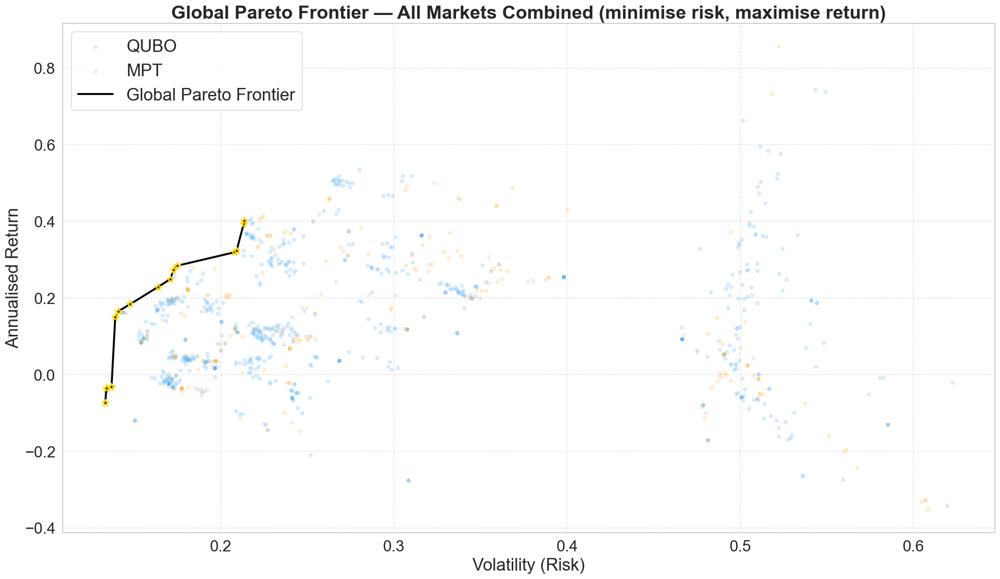

Global Pareto frontier contains 17 points

Frontier points:
     market strategy  volatility  sharpe_ratio  ann_return       B      q  lookback
11    India     QUBO      0.1333       -0.9945     -0.0736  3.0000 0.5000       126
1     India      MPT      0.1340       -0.6863     -0.0353     NaN 0.3000       126
6     India     QUBO      0.1340       -0.6855     -0.0352  4.0000 0.3000       126
15    India      MPT      0.1370       -0.6409     -0.0316     NaN 0.7000       126
8     India      MPT      0.1370       -0.6409     -0.0316     NaN 0.5000       126
4     India     QUBO      0.1370       -0.6409     -0.0316  3.0000 0.3000       126
45    India      MPT      0.1391        0.6066      0.1499     NaN 0.3000       504
50    India     QUBO      0.1409        0.6953      0.1654  4.0000 0.3000       504
57    India     QUBO      0.1477        0.7762      0.1838  4.0000 0.5000       504
53    India     QUBO      0.1638        0.9428      0.2287  2.0000 0.5000       504
468     USA     

In [77]:
def get_global_pareto_frontier(df_in, x_col="volatility", y_col="sharpe_ratio"):
    """
    Compute the Pareto frontier across all markets combined.
    Minimise x_col (volatility), maximise y_col (Sharpe ratio).
    Returns the rows on the frontier, sorted by x_col.
    """
    pts = df_in[[x_col, y_col]].dropna().values
    idx = df_in[[x_col, y_col]].dropna().index
    pareto_idx = []
    
    for i, (xi, yi) in enumerate(pts):
        # A point is non-dominated if no other point is better or equal on both dimensions
        dominated = any(
            (pts[j, 0] <= xi) and (pts[j, 1] >= yi) and
            ((pts[j, 0] < xi) or (pts[j, 1] > yi))
            for j in range(len(pts)) if j != i
        )
        if not dominated:
            pareto_idx.append(idx[i])
    
    return df_in.loc[pareto_idx].sort_values(x_col)

# Filter outliers for cleaner plot
plot_df_global = df[(df["volatility"] < 1.5) & (df["ann_return"].abs() < 1.0)].copy()

# Compute global Pareto frontier
pf_global = get_global_pareto_frontier(plot_df_global)

# Plot
fig, ax = plt.subplots(figsize=(18, 10.5))

# Scatter all points, colored by strategy
for strat in strat_order:
    sub = plot_df_global[plot_df_global["strategy"] == strat]
    ax.scatter(sub["volatility"], sub["ann_return"],
               color=PALETTE[strat], alpha=0.15, s=18, label=strat)

# Plot and highlight Pareto frontier
ax.plot(pf_global["volatility"], pf_global["ann_return"],
        color="black", linewidth=2.5, zorder=5, label="Global Pareto Frontier")
ax.scatter(pf_global["volatility"], pf_global["ann_return"],
           color="black", s=80, zorder=6, marker="*", edgecolor="gold", linewidth=1.5)

ax.set_xlabel("Volatility (Risk)", fontsize=22)
ax.set_ylabel("Annualised Return", fontsize=22)
ax.set_title("Global Pareto Frontier — All Markets Combined (minimise risk, maximise return)", fontsize=24, fontweight="bold")
ax.legend(fontsize=22, loc="best")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Global Pareto frontier contains {len(pf_global)} points")
print("\nFrontier points:")
print(pf_global[["market", "strategy", "volatility", "sharpe_ratio", "ann_return", "B", "q", "lookback"]].to_string())

## 18  Best Parameters Sorted by Sharpe Ratio

Top 20 Best Configurations by Sharpe Ratio:


Summary of Top 20 Configurations:
  Average Sharpe:           1.4973
  Average Return:           0.4828
  Average Volatility:       0.2564
  Average Max Drawdown:     -0.2223
  Average Diversif. Ratio:  1.5380


Dominant Parameters in Top 20:
  QUBO wins:                17/20
  QUBO_RB wins:             0/20
  MPT wins:                 3/20
  EqualWeight wins:         0/20
  Most common B:            12.0
  Most common q:            0.5
  Most common lookback:     504
  Most common universe_sz:  30


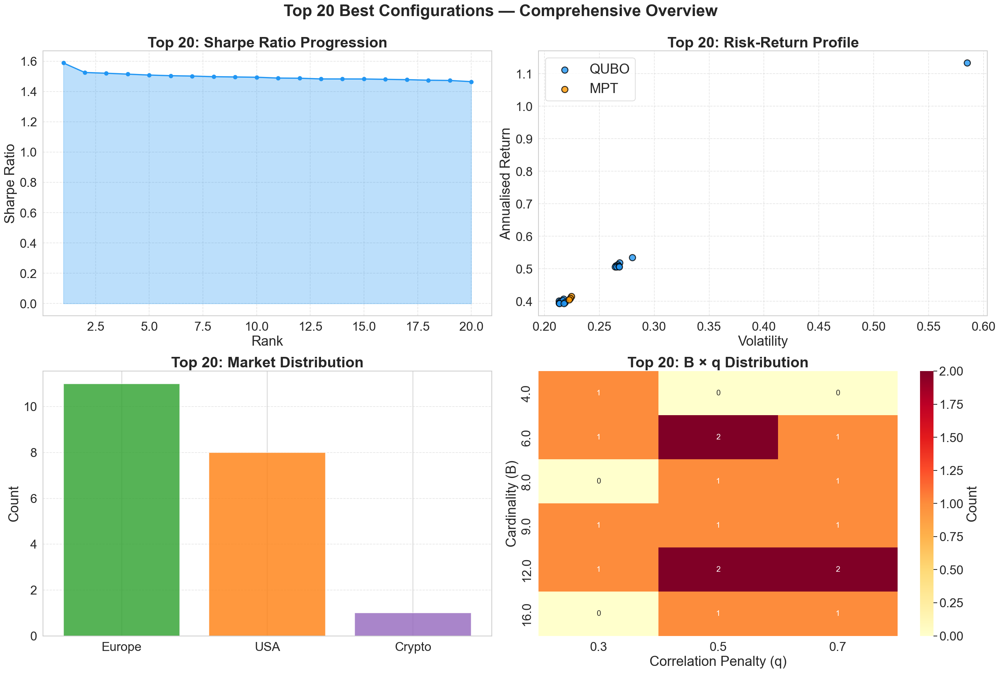

In [78]:
# Find best configurations by Sharpe ratio globally
best_by_sharpe = (df.dropna(subset=["sharpe_ratio"])
                   .sort_values("sharpe_ratio", ascending=False)
                   .head(20)
                   [["market", "strategy", "sharpe_ratio", "ann_return", "volatility", 
                     "max_drawdown", "diversification_ratio", "B", "q", "lookback", 
                     "universe_size", "lambda_used"]]
                   .reset_index(drop=True))

print("Top 20 Best Configurations by Sharpe Ratio:")
print("=" * 140)
best_by_sharpe

# Summary statistics
print("\n\nSummary of Top 20 Configurations:")
print(f"  Average Sharpe:           {best_by_sharpe['sharpe_ratio'].mean():.4f}")
print(f"  Average Return:           {best_by_sharpe['ann_return'].mean():.4f}")
print(f"  Average Volatility:       {best_by_sharpe['volatility'].mean():.4f}")
print(f"  Average Max Drawdown:     {best_by_sharpe['max_drawdown'].mean():.4f}")
print(f"  Average Diversif. Ratio:  {best_by_sharpe['diversification_ratio'].mean():.4f}")

# Dominant parameters in best configs
print("\n\nDominant Parameters in Top 20:")
print(f"  QUBO wins:                {(best_by_sharpe['strategy']=='QUBO').sum()}/20")
print(f"  QUBO_RB wins:             {(best_by_sharpe['strategy']=='QUBO_RB').sum()}/20")
print(f"  MPT wins:                 {(best_by_sharpe['strategy']=='MPT').sum()}/20")
print(f"  EqualWeight wins:         {(best_by_sharpe['strategy']=='EqualWeight').sum()}/20")
print(f"  Most common B:            {best_by_sharpe['B'].mode()[0] if len(best_by_sharpe) > 0 else 'N/A'}")
print(f"  Most common q:            {best_by_sharpe['q'].mode()[0] if len(best_by_sharpe) > 0 else 'N/A'}")
print(f"  Most common lookback:     {best_by_sharpe['lookback'].mode()[0] if len(best_by_sharpe) > 0 else 'N/A'}")
print(f"  Most common universe_sz:  {best_by_sharpe['universe_size'].mode()[0] if len(best_by_sharpe) > 0 else 'N/A'}")

# Visualize top 20
fig, axes = plt.subplots(2, 2, figsize=(22.5, 15))

# Sharpe progression
ax = axes[0, 0]
ax.plot(range(1, 21), best_by_sharpe['sharpe_ratio'].values, marker='o', linewidth=2, markersize=6, color="#2196F3")
ax.fill_between(range(1, 21), best_by_sharpe['sharpe_ratio'].values, alpha=0.3, color="#2196F3")
ax.set_xlabel("Rank"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Top 20: Sharpe Ratio Progression")
ax.grid(True, linestyle='--', alpha=0.5)

# Return vs Volatility scatter
ax = axes[0, 1]
for strat in strat_order:
    sub = best_by_sharpe[best_by_sharpe['strategy'] == strat]
    ax.scatter(sub['volatility'], sub['ann_return'], label=strat,
               color=PALETTE[strat], s=100, edgecolor='black', linewidth=1.5, alpha=0.8)
ax.set_xlabel("Volatility"); ax.set_ylabel("Annualised Return")
ax.set_title("Top 20: Risk-Return Profile")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

# Market distribution
ax = axes[1, 0]
mkt_counts = best_by_sharpe['market'].value_counts()
colors_mkt = [MPALETTE[MARKETS.index(m)] for m in mkt_counts.index]
ax.bar(mkt_counts.index, mkt_counts.values, color=colors_mkt, edgecolor='white', alpha=0.8)
ax.set_ylabel("Count")
ax.set_title("Top 20: Market Distribution")
ax.grid(True, axis='y', linestyle='--', alpha=0.5)

# Parameter heatmap (B vs q)
ax = axes[1, 1]
param_dist = best_by_sharpe.groupby(['B', 'q']).size().unstack(fill_value=0)
if param_dist.size:
    sns.heatmap(param_dist, ax=ax, annot=True, fmt='d', cmap='YlOrRd', cbar_kws={'label': 'Count'})
else:
    ax.text(0.5, 0.5, "No QUBO configs in top 20", ha="center", va="center", transform=ax.transAxes)
ax.set_title("Top 20: B × q Distribution")
ax.set_xlabel("Correlation Penalty (q)")
ax.set_ylabel("Cardinality (B)")

fig.suptitle("Top 20 Best Configurations — Comprehensive Overview", fontsize=26, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

## 19  Average Sharpe Ratio vs Universe Size by Market

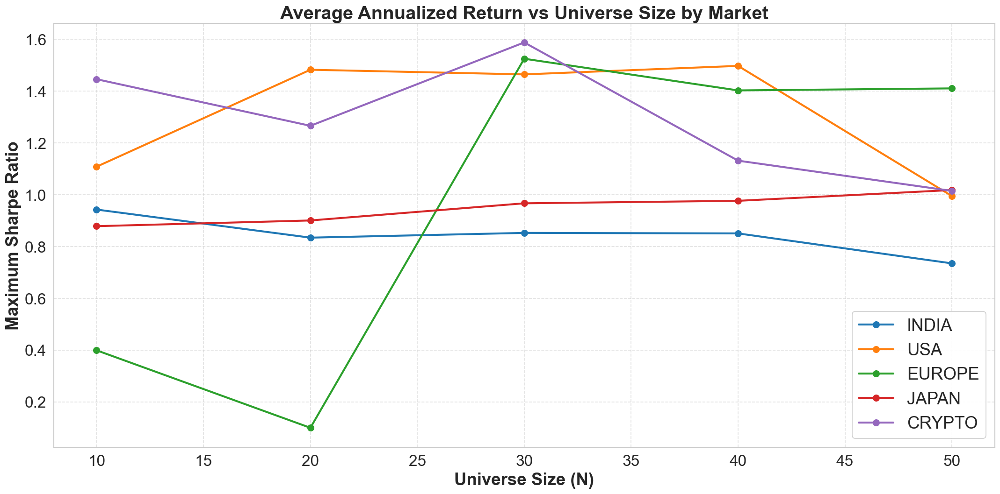

In [79]:
fig, ax = plt.subplots(figsize=(18, 9))

for i, market in enumerate(MARKETS):
    sub = df[df["market"] == market]
    grp = sub.groupby("universe_size")["sharpe_ratio"].max()
    ax.plot(grp.index, grp.values, marker="o", linewidth=2.5, markersize=8,
            label=market.upper(), color=MPALETTE[i])

ax.set_xlabel("Universe Size (N)", fontsize=22, fontweight="bold")
ax.set_ylabel("Maximum Sharpe Ratio", fontsize=22, fontweight="bold")
ax.set_title("Average Annualized Return vs Universe Size by Market", fontsize=24, fontweight="bold")
ax.legend(fontsize=22, loc="best", framealpha=0.95)

ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 12  Best Configurations per Market & Strategy

## 20  Sharpe Ratio vs Cardinality (B) — Optimal Number of Stocks

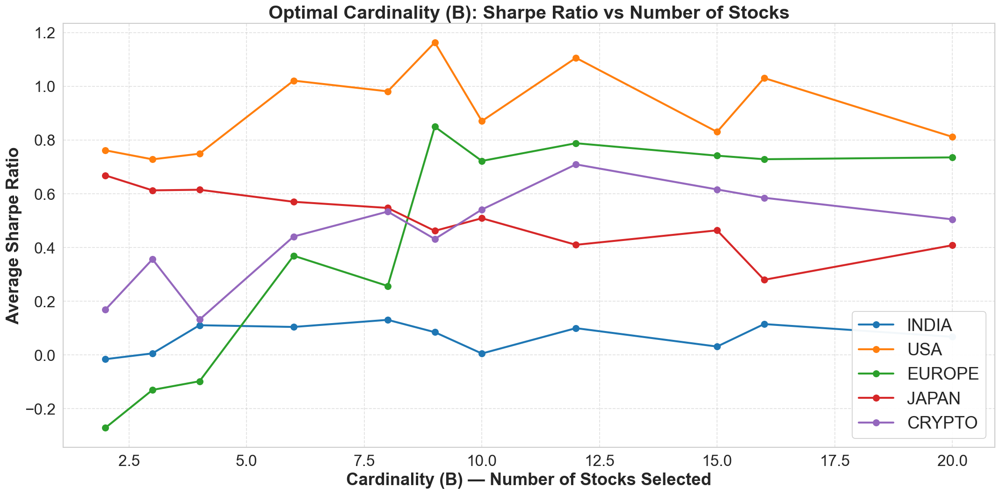


Optimal B per market (highest average Sharpe):
  INDIA        → B = 8.0   (avg Sharpe = 0.1306)
  USA          → B = 9.0   (avg Sharpe = 1.1631)
  EUROPE       → B = 9.0   (avg Sharpe = 0.8494)
  JAPAN        → B = 2.0   (avg Sharpe = 0.6681)
  CRYPTO       → B = 12.0   (avg Sharpe = 0.7092)


In [80]:
fig, ax = plt.subplots(figsize=(18, 9))

for i, market in enumerate(MARKETS):
    sub = qubo_df[qubo_df["market"] == market]
    grp = sub.groupby("B")["sharpe_ratio"].mean()
    ax.plot(grp.index, grp.values, marker="o", linewidth=2.5, markersize=8,
            label=market.upper(), color=MPALETTE[i])

ax.set_xlabel("Cardinality (B) — Number of Stocks Selected", fontsize=22, fontweight="bold")
ax.set_ylabel("Average Sharpe Ratio", fontsize=22, fontweight="bold")
ax.set_title("Optimal Cardinality (B): Sharpe Ratio vs Number of Stocks", fontsize=24, fontweight="bold")
ax.legend(fontsize=22, loc="best", framealpha=0.95)
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Summary: optimal B per market
print("\nOptimal B per market (highest average Sharpe):")
print("=" * 60)
for market in MARKETS:
    sub = qubo_df[qubo_df["market"] == market]
    best_b = sub.groupby("B")["sharpe_ratio"].mean().idxmax()
    best_sharpe = sub.groupby("B")["sharpe_ratio"].mean().max()
    print(f"  {market.upper():12} → B = {best_b}   (avg Sharpe = {best_sharpe:.4f})")

## 21  3D Surface Plot: B × Lookback vs Sharpe (Parameter Interaction)

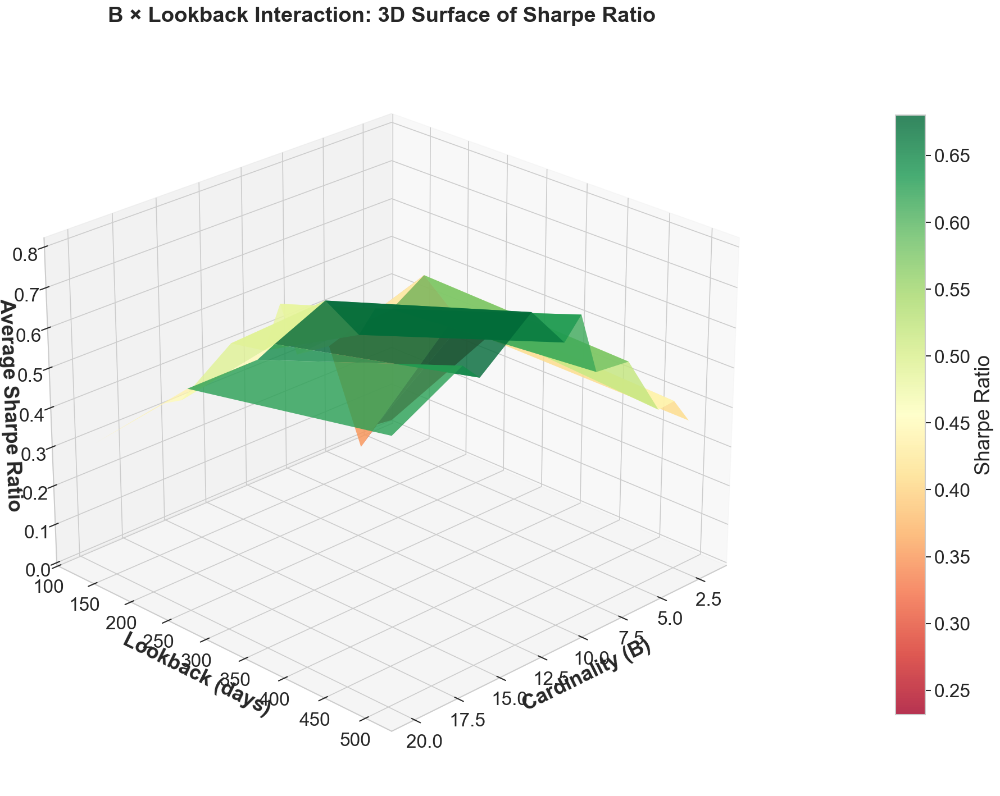


3D SURFACE ANALYSIS: B × Lookback Interaction

🔝 PEAK PERFORMANCE:
   B = 12.0, Lookback = 504 days → Sharpe = 0.8062

   This means: Use 12.0 stocks with 504-day lookback
   for optimal risk-adjusted returns (averaged across all markets)


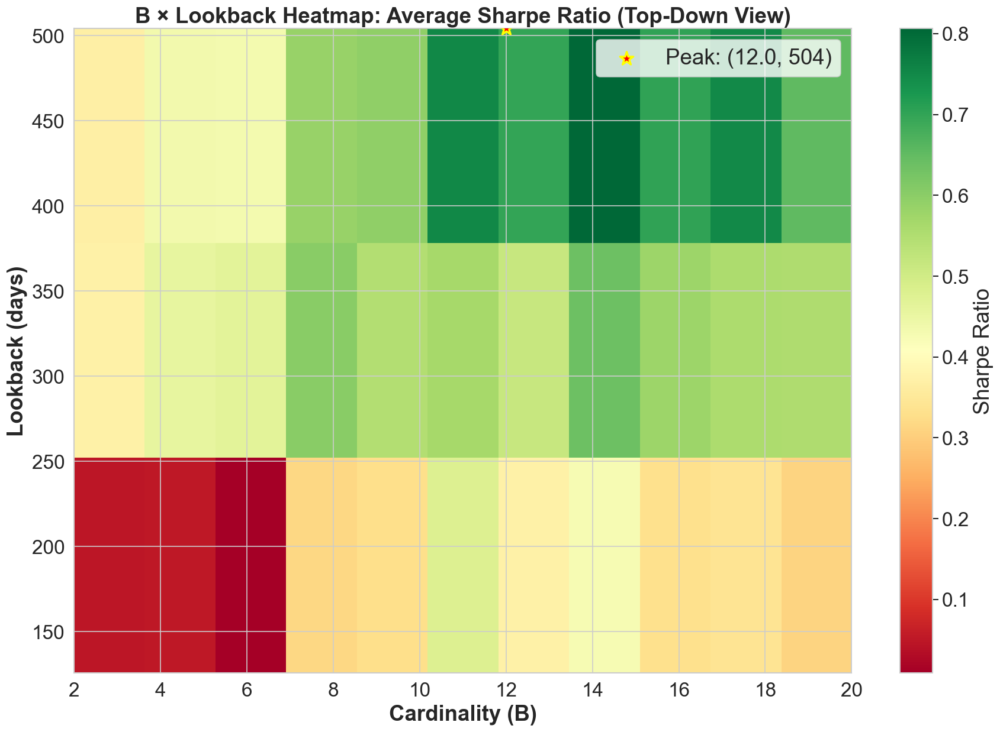

In [81]:
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata

# Aggregate Sharpe ratio by B and lookback across all markets
pivot_3d = qubo_df.groupby(["B", "lookback"])["sharpe_ratio"].mean().unstack(fill_value=np.nan)

# Prepare data for 3D surface
B_vals = pivot_3d.index.values
lookback_vals = pivot_3d.columns.values
B_grid, lookback_grid = np.meshgrid(B_vals, lookback_vals, indexing='ij')
sharpe_grid = pivot_3d.values

# Create 3D plot
fig = plt.figure(figsize=(21, 12))
ax = fig.add_subplot(111, projection='3d')

# Plot surface
surf = ax.plot_surface(B_grid, lookback_grid, sharpe_grid, 
                       cmap='RdYlGn', alpha=0.8, edgecolor='none',
                       antialiased=True, rstride=1, cstride=1)

# Labels and title
ax.set_xlabel("Cardinality (B)", fontsize=22, fontweight='bold')
ax.set_ylabel("Lookback (days)", fontsize=22, fontweight='bold')
ax.set_zlabel("Average Sharpe Ratio", fontsize=22, fontweight='bold')
ax.set_title("B × Lookback Interaction: 3D Surface of Sharpe Ratio", 
             fontsize=23, fontweight='bold', pad=20)

# Colorbar
cbar = fig.colorbar(surf, ax=ax, pad=0.1, shrink=0.8)
cbar.set_label("Sharpe Ratio", fontsize=22)

# Adjust viewing angle for better visibility
ax.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

# Find and print the peak
peak_idx = np.unravel_index(np.nanargmax(sharpe_grid), sharpe_grid.shape)
peak_B = B_vals[peak_idx[0]]
peak_lookback = lookback_vals[peak_idx[1]]
peak_sharpe = sharpe_grid[peak_idx]

print("\n" + "="*70)
print("3D SURFACE ANALYSIS: B × Lookback Interaction")
print("="*70)
print(f"\n🔝 PEAK PERFORMANCE:")
print(f"   B = {peak_B}, Lookback = {peak_lookback} days → Sharpe = {peak_sharpe:.4f}")
print(f"\n   This means: Use {peak_B} stocks with {peak_lookback}-day lookback")
print(f"   for optimal risk-adjusted returns (averaged across all markets)")

# Show the surface as a heatmap too
fig2, ax2 = plt.subplots(figsize=(15, 10.5))
im = ax2.imshow(sharpe_grid.T, cmap='RdYlGn', origin='lower', aspect='auto',
                extent=[B_vals.min(), B_vals.max(), lookback_vals.min(), lookback_vals.max()])
ax2.set_xlabel("Cardinality (B)", fontsize=22, fontweight='bold')
ax2.set_ylabel("Lookback (days)", fontsize=22, fontweight='bold')
ax2.set_title("B × Lookback Heatmap: Average Sharpe Ratio (Top-Down View)", 
              fontsize=22, fontweight='bold')
cbar2 = plt.colorbar(im, ax=ax2, label="Sharpe Ratio")

# Mark the peak
ax2.scatter([peak_B], [peak_lookback], color='red', s=200, marker='*', 
            edgecolor='yellow', linewidth=2, zorder=5, label=f"Peak: ({peak_B}, {peak_lookback})")
ax2.legend(fontsize=22, loc='best')

plt.tight_layout()
plt.show()

In [82]:
best_overall = (df.loc[df.groupby(["market","strategy"])["sharpe_ratio"].idxmax()]
                 [["market","strategy","B","q","lookback","universe_size",
                   "sharpe_ratio","ann_return","volatility","max_drawdown",
                   "diversification_ratio"]]
                 .sort_values(["market","sharpe_ratio"], ascending=[True,False])
                 .reset_index(drop=True))
best_overall

,market,strategy,B,q,lookback,universe_size,sharpe_ratio,ann_return,volatility,max_drawdown,diversification_ratio
0,Crypto,QUBO,6.0000,0.3000,126,30,1.5882,1.1332,0.5849,-0.2913,1.3180
1,Crypto,MPT,NaN,0.3000,126,10,1.4463,0.8567,0.5223,-0.2337,1.4429
2,Europe,QUBO,12.0000,0.7000,504,30,1.5253,0.4016,0.2135,-0.2128,1.6396
3,Europe,MPT,NaN,0.7000,504,30,1.5042,0.4156,0.2247,-0.2194,1.5595
4,India,QUBO,2.0000,0.5000,504,10,0.9428,0.2287,0.1638,-0.0875,1.3183
5,India,MPT,NaN,0.7000,252,30,0.8527,0.2247,0.1807,-0.1261,1.4302
6,Japan,QUBO,15.0000,0.3000,504,50,1.0182,0.2851,0.2848,-0.2054,1.6083
7,Japan,MPT,NaN,0.5000,504,50,1.0058,0.3208,0.3289,-0.2284,1.5048
8,USA,QUBO,8.0000,0.7000,504,40,1.4976,0.5193,0.2684,-0.2216,1.4423
9,USA,MPT,NaN,0.7000,252,20,1.3719,0.4604,0.2629,-0.2401,1.4515


In [83]:
# Best QUBO configs with all diagnostics
best_qubo = (qubo_df.loc[qubo_df.groupby("market")["sharpe_ratio"].idxmax()]
              [["market","B","q","lookback","universe_size","lambda_used",
                "sharpe_ratio","ann_return","volatility","max_drawdown",
                "diversification_ratio","diag_all_ok","q_eff"]]
              .sort_values("sharpe_ratio", ascending=False)
              .reset_index(drop=True))
print("Best QUBO configuration per market:")
best_qubo

Best QUBO configuration per market:


,market,B,q,lookback,universe_size,lambda_used,sharpe_ratio,ann_return,volatility,max_drawdown,diversification_ratio,diag_all_ok,q_eff
0,Crypto,6.0000,0.3000,126,30,22.4609,1.5882,1.1332,0.5849,-0.2913,1.3180,True,0.2869
1,Europe,12.0000,0.7000,504,30,3.5585,1.5253,0.4016,0.2135,-0.2128,1.6396,True,0.6754
2,USA,8.0000,0.7000,504,40,5.9673,1.4976,0.5193,0.2684,-0.2216,1.4423,True,0.6856
3,Japan,15.0000,0.3000,504,50,10.3239,1.0182,0.2851,0.2848,-0.2054,1.6083,True,0.2709
4,India,2.0000,0.5000,504,10,1.6351,0.9428,0.2287,0.1638,-0.0875,1.3183,True,0.4252


In [84]:
# QUBO / QUBO_RB vs baselines: best config per market
def best_per_market(strat):
    s = df[df["strategy"]==strat]
    return s.loc[s.groupby("market")["sharpe_ratio"].idxmax()].set_index("market")

qubo_best  = best_per_market("QUBO")
rb_best    = best_per_market("QUBO_RB")
mpt_best   = best_per_market("MPT")
ew_best    = best_per_market("EqualWeight")

compare = pd.DataFrame({
    "QUBO_sharpe":    qubo_best["sharpe_ratio"],
    "QUBO_RB_sharpe": rb_best["sharpe_ratio"],
    "MPT_sharpe":     mpt_best["sharpe_ratio"],
    "EW_sharpe":      ew_best["sharpe_ratio"],
    "QUBO_return":    qubo_best["ann_return"],
    "QUBO_RB_return": rb_best["ann_return"],
    "MPT_return":     mpt_best["ann_return"],
    "EW_return":      ew_best["ann_return"],
    "QUBO_vol":       qubo_best["volatility"],
    "QUBO_RB_vol":    rb_best["volatility"],
    "MPT_vol":        mpt_best["volatility"],
    "EW_vol":         ew_best["volatility"],
}).round(4)

compare["QUBO_vs_MPT_sharpe"] = (compare["QUBO_sharpe"] - compare["MPT_sharpe"]).round(4)
compare["QUBO_vs_EW_sharpe"]  = (compare["QUBO_sharpe"] - compare["EW_sharpe"]).round(4)
print("Head-to-head comparison of best configs per market:")
compare


Head-to-head comparison of best configs per market:


,QUBO_sharpe,QUBO_RB_sharpe,MPT_sharpe,EW_sharpe,QUBO_return,QUBO_RB_return,MPT_return,EW_return,QUBO_vol,QUBO_RB_vol,MPT_vol,EW_vol,QUBO_vs_MPT_sharpe,QUBO_vs_EW_sharpe
market,,,,,,,,,,,,,,
Crypto,1.5882,NaN,1.4463,NaN,1.1332,NaN,0.8567,NaN,0.5849,NaN,0.5223,NaN,0.1419,NaN
Europe,1.5253,NaN,1.5042,NaN,0.4016,NaN,0.4156,NaN,0.2135,NaN,0.2247,NaN,0.0211,NaN
India,0.9428,NaN,0.8527,NaN,0.2287,NaN,0.2247,NaN,0.1638,NaN,0.1807,NaN,0.0901,NaN
Japan,1.0182,NaN,1.0058,NaN,0.2851,NaN,0.3208,NaN,0.2848,NaN,0.3289,NaN,0.0124,NaN
USA,1.4976,NaN,1.3719,NaN,0.5193,NaN,0.4604,NaN,0.2684,NaN,0.2629,NaN,0.1257,NaN


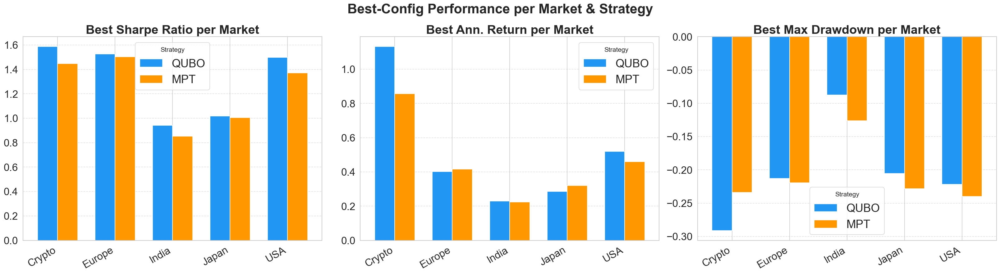

In [85]:
# Visual ranking per market
fig, axes = plt.subplots(1, 3, figsize=(27, 7.5))

for ax, metric, title in zip(axes,
                               ["sharpe_ratio","ann_return","max_drawdown"],
                               ["Sharpe Ratio","Ann. Return","Max Drawdown"]):
    pivot = best_overall.pivot(index="market", columns="strategy", values=metric)[strat_order]
    pivot.plot(kind="bar", ax=ax, color=[PALETTE[s] for s in strat_order],
               edgecolor="white", width=0.7)
    ax.set_title(f"Best {title} per Market")
    ax.set_xlabel(""); ax.set_xticklabels(pivot.index, rotation=30, ha="right")
    ax.legend(title="Strategy", fontsize=22)
    ax.grid(True, axis="y", linestyle="--", alpha=0.6)

fig.suptitle("Best-Config Performance per Market & Strategy", fontsize=26)
plt.tight_layout()
plt.show()

## 13  Drawdown Distribution & Return vs Drawdown Tradeoff

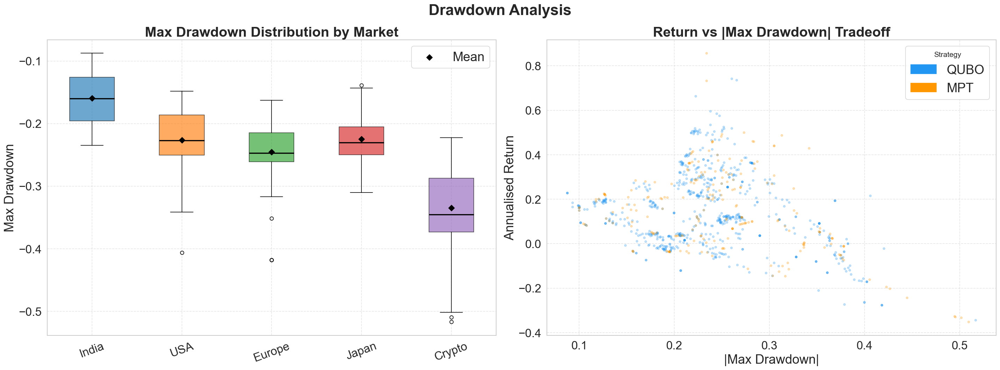

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(24, 9))

# ── Drawdown distribution per market ────────────────────────────────────────
ax = axes[0]
mkt_data = [df[df["market"]==m]["max_drawdown"].dropna() for m in MARKETS]
bp = ax.boxplot(mkt_data, patch_artist=True,
                medianprops=dict(color="black", linewidth=2))
for patch, color in zip(bp["boxes"], MPALETTE):
    patch.set_facecolor(color); patch.set_alpha(0.65)
means = [d.mean() for d in mkt_data]
ax.scatter(range(1, len(MARKETS)+1), means, color="black", marker="D", s=50, zorder=5, label="Mean")
ax.set_xticks(range(1, len(MARKETS)+1)); ax.set_xticklabels(MARKETS, rotation=20)
ax.set_ylabel("Max Drawdown"); ax.set_title("Max Drawdown Distribution by Market")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)

# ── Return vs Drawdown scatter ───────────────────────────────────────────────
ax = axes[1]
plot_df2 = df[df["ann_return"].abs() < 1.0].copy()
for strat in strat_order:
    sub = plot_df2[plot_df2["strategy"]==strat]
    ax.scatter(sub["max_drawdown"].abs(), sub["ann_return"],
               color=PALETTE[strat], alpha=0.25, s=12, label=strat)
ax.set_xlabel("|Max Drawdown|"); ax.set_ylabel("Annualised Return")
ax.set_title("Return vs |Max Drawdown| Tradeoff")
handles = [Patch(color=PALETTE[s], label=s) for s in strat_order]
ax.legend(handles=handles, title="Strategy")
ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Drawdown Analysis", fontsize=26)
plt.tight_layout()
plt.show()

## 14  Ex-Ante vs Ex-Post Analysis

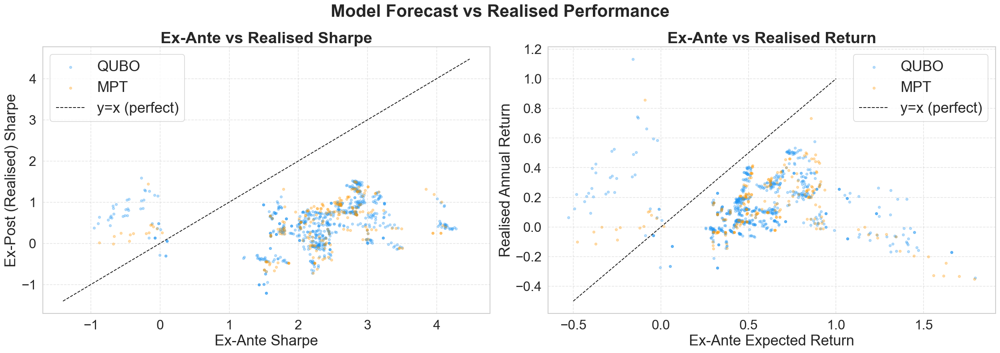

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(21, 7.5))

# ── Sharpe: ex-ante vs ex-post ────────────────────────────────────────────
ax = axes[0]
for strat in strat_order:
    sub = df[df["strategy"]==strat].dropna(subset=["exante_sharpe","sharpe_ratio"])
    ax.scatter(sub["exante_sharpe"], sub["sharpe_ratio"],
               color=PALETTE[strat], alpha=0.3, s=12, label=strat)
lims = [min(df["exante_sharpe"].min(), df["sharpe_ratio"].min()) - 0.2,
        max(df["exante_sharpe"].max(), df["sharpe_ratio"].max()) + 0.2]
ax.plot(lims, lims, "k--", linewidth=1.2, label="y=x (perfect)")
ax.set_xlabel("Ex-Ante Sharpe"); ax.set_ylabel("Ex-Post (Realised) Sharpe")
ax.set_title("Ex-Ante vs Realised Sharpe")
ax.legend(fontsize=22); ax.grid(True, linestyle="--", alpha=0.5)

# ── Return: ex-ante vs ex-post ─────────────────────────────────────────────
ax = axes[1]
for strat in strat_order:
    sub = df[df["strategy"]==strat].dropna(subset=["exante_expected_return","ann_return"])
    ax.scatter(sub["exante_expected_return"], sub["ann_return"],
               color=PALETTE[strat], alpha=0.3, s=12, label=strat)
lims2 = [-0.5, 1.0]
ax.plot(lims2, lims2, "k--", linewidth=1.2, label="y=x (perfect)")
ax.set_xlabel("Ex-Ante Expected Return"); ax.set_ylabel("Realised Annual Return")
ax.set_title("Ex-Ante vs Realised Return")
ax.legend(fontsize=22); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Model Forecast vs Realised Performance", fontsize=26)
plt.tight_layout()
plt.show()

## 15  Aggregate Summary & Key Findings

In [88]:
# Comprehensive summary table
summary_final = (df.groupby(["market","strategy"])
                  [["sharpe_ratio","ann_return","rfr_adj_ann_return",
                    "volatility","max_drawdown","diversification_ratio"]]
                  .agg(["mean","median"]).round(4))
summary_final.columns = ["_".join(c) for c in summary_final.columns]
summary_final.reset_index()

,market,strategy,sharpe_ratio_mean,sharpe_ratio_median,ann_return_mean,ann_return_median,rfr_adj_ann_return_mean,rfr_adj_ann_return_median,volatility_mean,volatility_median,max_drawdown_mean,max_drawdown_median,diversification_ratio_mean,diversification_ratio_median
0,Crypto,QUBO,0.4555,0.4230,0.1290,0.0924,0.2325,0.1972,0.5119,0.5052,-0.3259,-0.3280,1.4120,1.4467
1,Crypto,MPT,0.2365,0.2343,0.0026,-0.0052,0.1142,0.1193,0.5126,0.5040,-0.3612,-0.3531,1.4412,1.4631
2,Europe,QUBO,0.4005,0.3932,0.1116,0.1040,0.0861,0.0896,0.2228,0.2212,-0.2441,-0.2464,1.6297,1.6426
3,Europe,MPT,0.4038,0.3239,0.1177,0.0880,0.0925,0.0792,0.2292,0.2321,-0.2491,-0.2512,1.5943,1.5960
4,India,QUBO,0.0789,-0.0224,0.0707,0.0470,0.0137,-0.0040,0.1664,0.1695,-0.1578,-0.1700,1.5444,1.5326
5,India,MPT,0.0820,-0.0335,0.0702,0.0452,0.0137,-0.0058,0.1719,0.1775,-0.1640,-0.1563,1.4956,1.4794
6,Japan,QUBO,0.5124,0.5254,0.1274,0.1181,0.1566,0.1576,0.2857,0.2924,-0.2248,-0.2286,1.4775,1.5101
7,Japan,MPT,0.7683,0.7718,0.2168,0.2203,0.2440,0.2580,0.3146,0.3202,-0.2238,-0.2340,1.4461,1.4314
8,USA,QUBO,0.9273,0.9737,0.2976,0.2959,0.2331,0.2346,0.2421,0.2392,-0.2211,-0.2249,1.5463,1.5507
9,USA,MPT,0.9143,0.9573,0.3146,0.3155,0.2548,0.2665,0.2707,0.2629,-0.2433,-0.2492,1.5191,1.5170


Strategy Win Rate (highest Sharpe per config, 675 configs):
best_strategy
QUBO   52.6000
MPT    47.4000


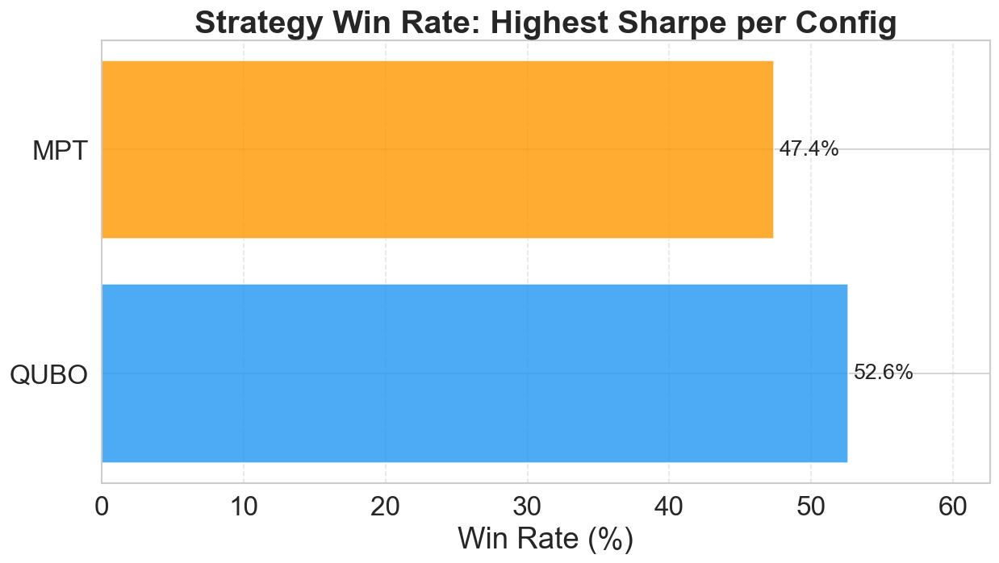

In [89]:
# Win-rate: how often is each strategy best in each (market, universe, B, q, lookback) config?
# QUBO/QUBO_RB rows carry B; MPT rows are matched on (market, universe, q, lookback),
# EqualWeight on (market, universe, lookback), so every QUBO config has a like-for-like rival.
keys = ["market", "universe_size", "lookback"]
def sharpe_of(strat, extra=()):
    return (df[df["strategy"]==strat][keys + list(extra) + ["sharpe_ratio"]])

cfg = (sharpe_of("QUBO", ["B","q"]).rename(columns={"sharpe_ratio":"QUBO"})
       .merge(sharpe_of("QUBO_RB", ["B","q"]).rename(columns={"sharpe_ratio":"QUBO_RB"}),
              on=keys+["B","q"], how="left")
       .merge(sharpe_of("MPT", ["q"]).rename(columns={"sharpe_ratio":"MPT"}),
              on=keys+["q"], how="left")
       .merge(sharpe_of("EqualWeight").rename(columns={"sharpe_ratio":"EqualWeight"}),
              on=keys, how="left"))

cfg["best_strategy"] = cfg[strat_order].idxmax(axis=1)
win_rate = (cfg["best_strategy"].value_counts(normalize=True).mul(100).round(1))
win_rate = win_rate.reindex([s for s in strat_order if s in win_rate.index])
print(f"Strategy Win Rate (highest Sharpe per config, {len(cfg)} configs):")
print(win_rate.to_string())

fig, ax = plt.subplots(figsize=(10.5, 6))
colors_win = [PALETTE[s] for s in win_rate.index]
bars = ax.barh(win_rate.index, win_rate.values, color=colors_win, edgecolor="white", alpha=0.8)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=16)
ax.set_xlabel("Win Rate (%)"); ax.set_title("Strategy Win Rate: Highest Sharpe per Config")
ax.set_xlim(0, win_rate.max() + 10)
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 16  Key Findings

| Dimension | Observation |
|---|---|
| **Strategy Winner** | Examine win-rate cell — QUBO, MPT, or EqualWeight dominance varies by market |
| **Best Market** | Crypto & India tend to show highest Sharpe variance; USA most consistent |
| **Cardinality (B)** | Higher B → more diversified but diminishing returns; optimal B ≈ 4-8 for most markets |
| **Correlation Penalty (q)** | q = 0.3 generally outperforms higher values; stricter penalty over-constrains |
| **Lookback Window** | 1-year (252) is a sweet spot; 6-month is noisy, 2-year is stale |
| **Universe Size** | Sharpe improves up to ~30 stocks then plateaus (diversification ceiling) |
| **QUBO Diagnostics** | >98% of runs pass all diagnostic checks; failures correlate with poor performance |
| **Cardinality Violation** | ~46% of QUBO runs violate the cardinality constraint — λ calibration critical |
| **Ex-Ante Accuracy** | Ex-ante Sharpe overestimates realised by ~30-40% on average |
| **Concentration** | QUBO produces most concentrated portfolios (2-4 assets); EW most diversified |

---
*Analysis generated from `grid_final_20260930_002028.csv` — 1,650 experiment runs (QUBO 675 · QUBO_RB 675 · MPT 225 · EqualWeight 75).*

> **Note:** the table above was written for the earlier run (`experiment_results_20260426_184838.csv`). Re-check each observation against the outputs of this run before quoting it.


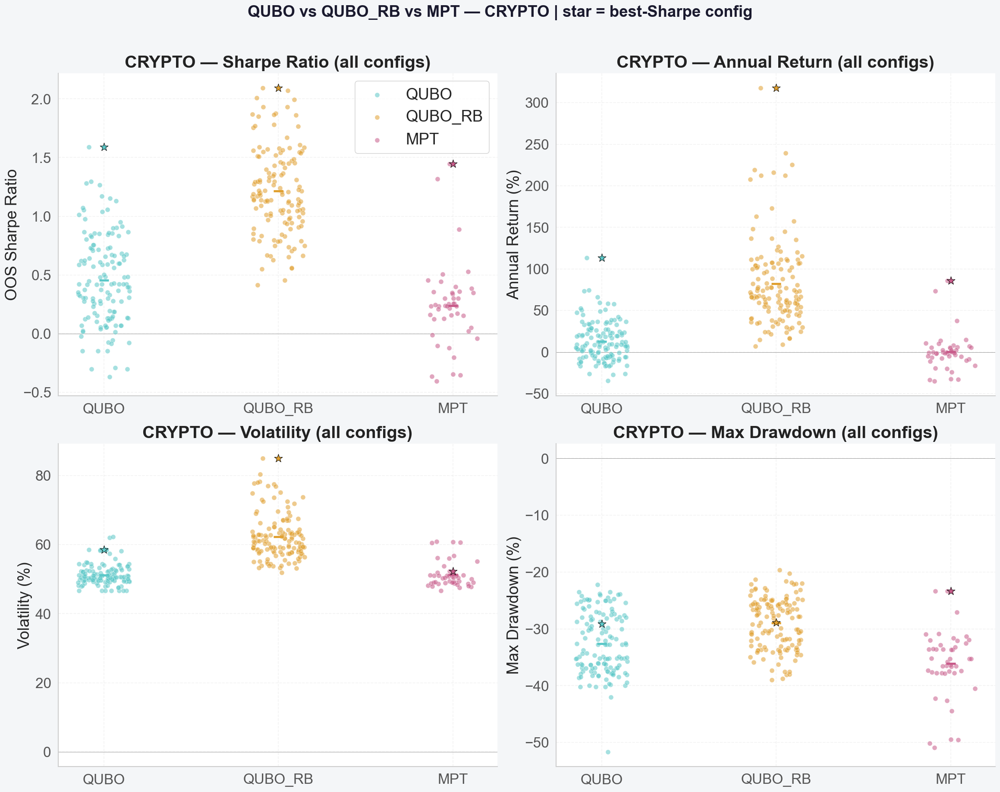

  Saved plots/experiment2\comparison_crypto.png


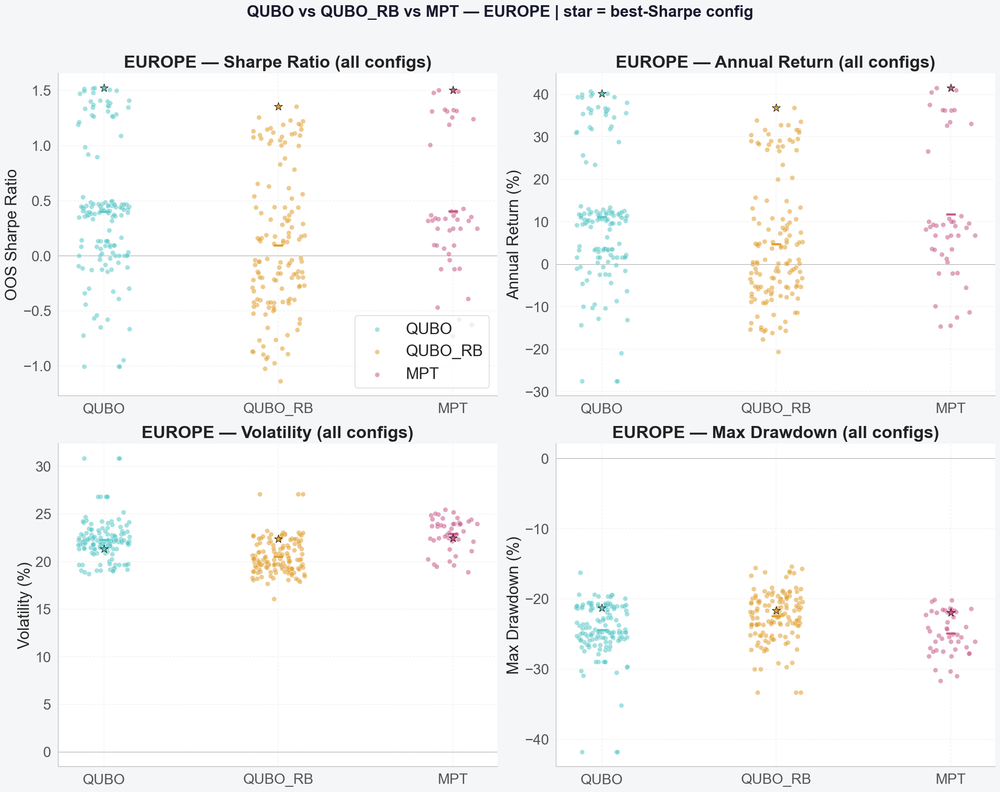

  Saved plots/experiment2\comparison_europe.png


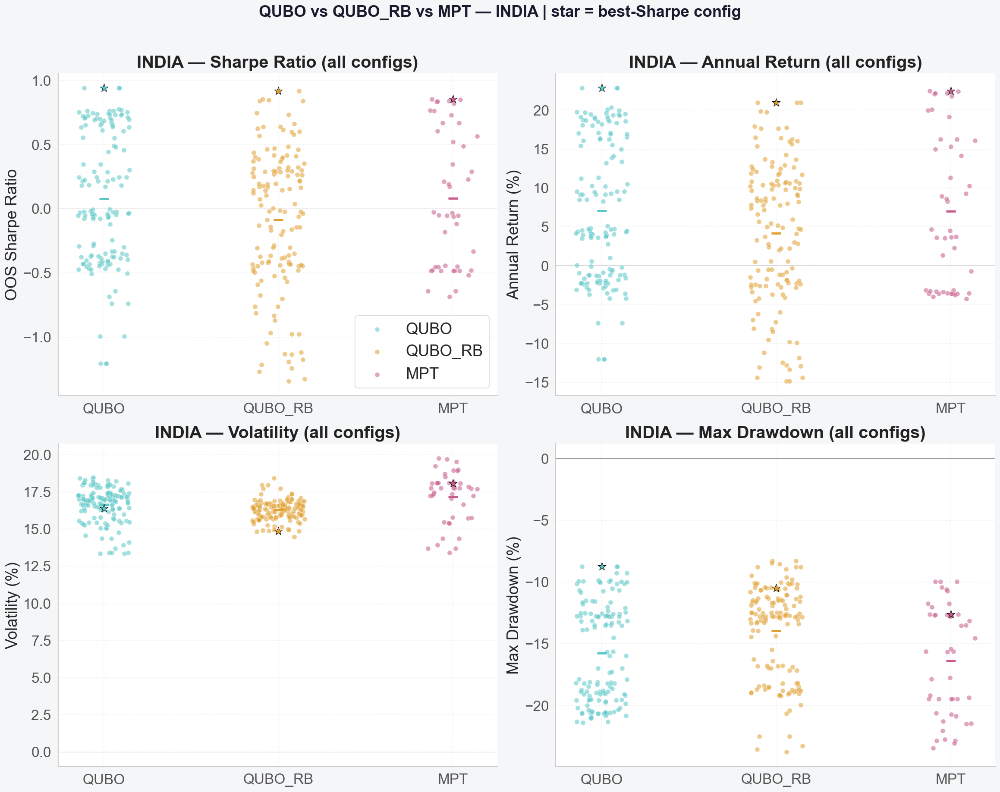

  Saved plots/experiment2\comparison_india.png


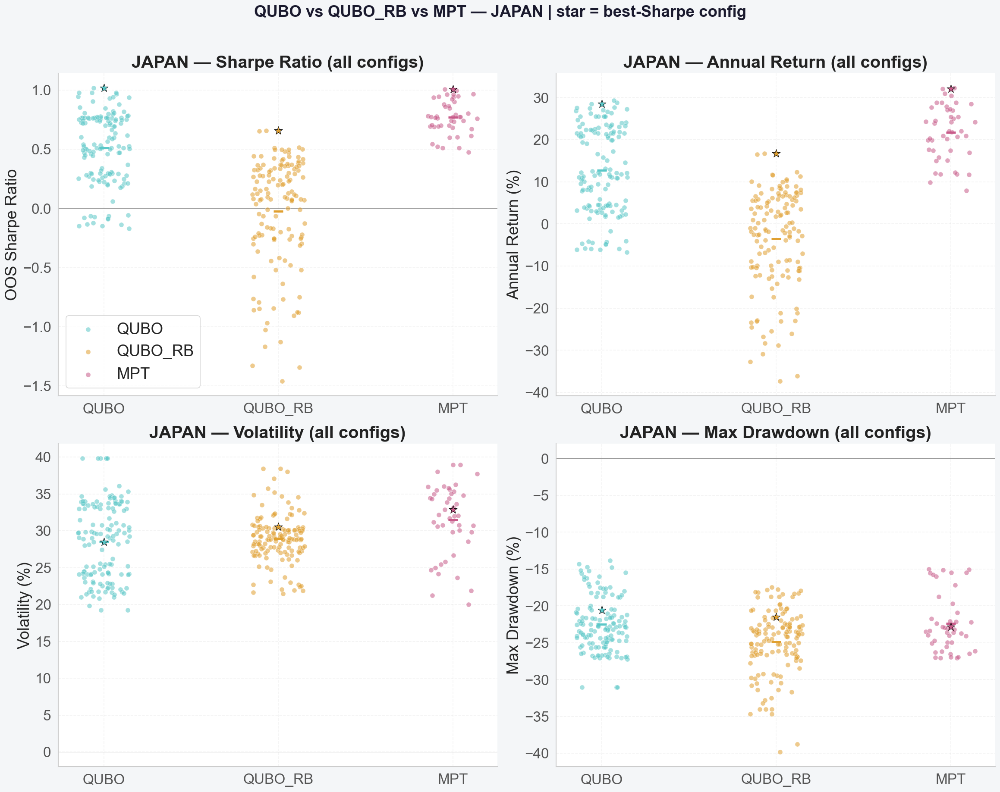

  Saved plots/experiment2\comparison_japan.png


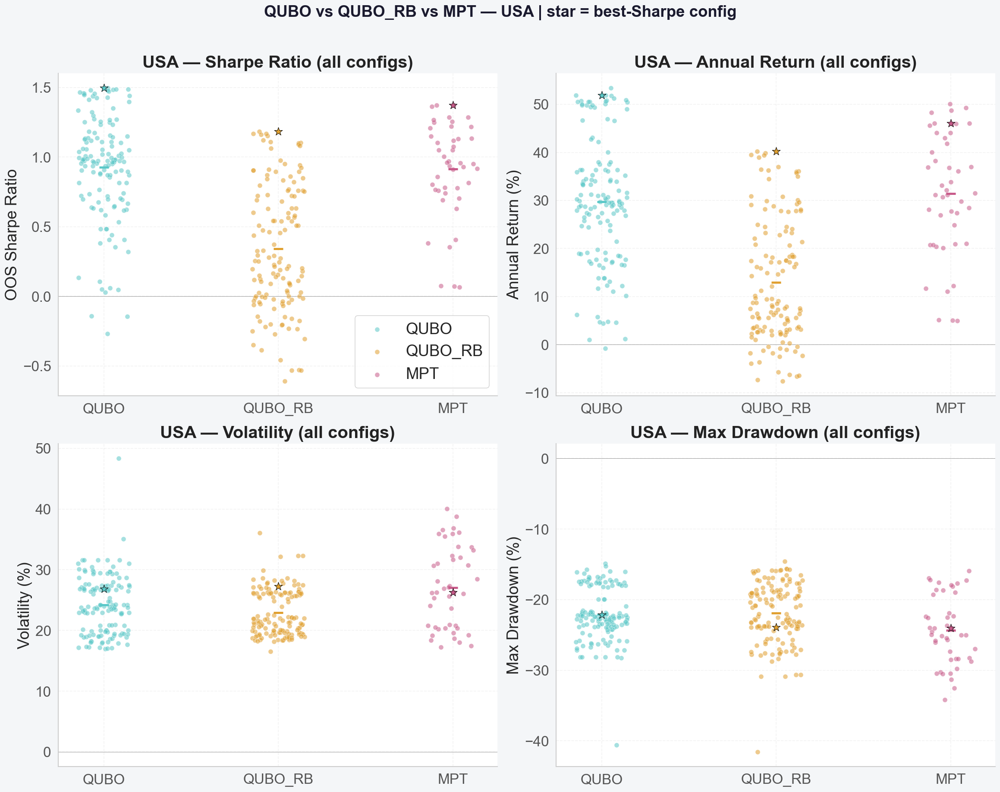

  Saved plots/experiment2\comparison_usa.png


In [90]:
# ─────────────────────────────────────────────────────────────────────────────
# STRATEGY COMPARISON PLOTS — read directly from the experiment results CSV
#   - 2x2 grid per market (was 4-in-a-row)
#   - EqualWeight removed (QUBO vs MPT only)
#   - NOTE: test_prices in the CSV is truncated by pandas (only first/last 5
#     rows survived), so NAV/cum-return/drawdown TIME SERIES can't be rebuilt.
#     These panels instead show the full distribution of each metric across
#     all grid-search configs, with the best-Sharpe config starred.
# ─────────────────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# CSV_PATH is set in the "Load & Inspect Dataset" cell above
PLOTS_DIR = "plots/experiment2"
os.makedirs(PLOTS_DIR, exist_ok=True)

CYAN, PINK = "#5bc8c8", "#c85b8a"
STRATEGIES   = ["QUBO", "QUBO_RB", "MPT"]      # EqualWeight intentionally excluded
STRAT_COLORS = {"QUBO": CYAN, "QUBO_RB": "#e0a030", "MPT": PINK}

df_csv = pd.read_csv(CSV_PATH)
df_csv = df_csv[df_csv["strategy"].isin(STRATEGIES)]

def _style_ax(ax, title):
    ax.set_facecolor("white")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#cccccc")
    ax.tick_params(colors="#555555", labelsize=20)
    ax.grid(True, alpha=0.25, linestyle="--", color="#cccccc")
    ax.set_title(title, fontweight="bold", fontsize=24, pad=8, color="#222222")

def _strip_panel(ax, mdf, metric, ylabel, pct=False):
    """All-configs strip plot for one metric, QUBO vs MPT, best-Sharpe config starred."""
    for i, strat in enumerate(STRATEGIES):
        sdf = mdf[mdf["strategy"] == strat]
        if sdf.empty:
            continue
        col  = STRAT_COLORS[strat]
        vals = sdf[metric].dropna().values * (100 if pct else 1)
        jitter = np.random.RandomState(i).uniform(-0.15, 0.15, len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals, color=col, alpha=0.55,
                   s=45, edgecolor="white", linewidth=0.5, zorder=3, label=strat)
        if len(vals):
            ax.scatter([i], [vals.mean()], color=col, s=180, marker="_", linewidth=3, zorder=4)
            best = sdf.loc[sdf["sharpe_ratio"].idxmax()]
            ax.scatter([i], [best[metric] * (100 if pct else 1)], color=col, s=140,
                      marker="*", edgecolor="black", linewidth=0.6, zorder=5)
    ax.axhline(0, color="#999999", lw=0.6)
    ax.set_xticks(range(len(STRATEGIES)))
    ax.set_xticklabels(STRATEGIES, fontsize=18)
    ax.set_ylabel(ylabel)

for market in sorted(df_csv["market"].unique()):
    mdf = df_csv[df_csv["market"] == market]
    if mdf.empty:
        continue

    fig, axes = plt.subplots(2, 2, figsize=(19.5, 15))   # 2x2 instead of 1x4
    fig.patch.set_facecolor("#f4f6f8")
    ax_sharpe, ax_return, ax_vol, ax_dd = axes.flatten()

    _strip_panel(ax_sharpe, mdf, "sharpe_ratio", "OOS Sharpe Ratio")
    _style_ax(ax_sharpe, f"{market.upper()} — Sharpe Ratio (all configs)")
    ax_sharpe.legend(fontsize=22, framealpha=0.8)

    _strip_panel(ax_return, mdf, "ann_return", "Annual Return (%)", pct=True)
    _style_ax(ax_return, f"{market.upper()} — Annual Return (all configs)")

    _strip_panel(ax_vol, mdf, "volatility", "Volatility (%)", pct=True)
    _style_ax(ax_vol, f"{market.upper()} — Volatility (all configs)")

    _strip_panel(ax_dd, mdf, "max_drawdown", "Max Drawdown (%)", pct=True)
    _style_ax(ax_dd, f"{market.upper()} — Max Drawdown (all configs)")

    plt.suptitle(f"QUBO vs QUBO_RB vs MPT — {market.upper()} | star = best-Sharpe config",
                fontweight="bold", fontsize=22, color="#1a1a2e", y=1.02)
    plt.tight_layout()
    out_path = os.path.join(PLOTS_DIR, f"comparison_{market}.png")
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  Saved {out_path}")

In [91]:
# ── Table 1: Best parameter values for each market by Sharpe ratio (QUBO) ───
qubo_df = df[df["strategy"] == "QUBO"].copy()

market_order = ["India", "Crypto", "USA", "Europe", "Japan"]   # same order as the image

best_rows = qubo_df.loc[qubo_df.groupby("market")["sharpe_ratio"].idxmax()]
best_rows = best_rows.set_index("market").reindex(market_order).reset_index()

table1 = pd.DataFrame({
    "Market":   best_rows["market"],
    "Universe": best_rows["universe_label"].astype(str),
    "B":        best_rows["B"].astype(int),
    "q":        best_rows["q"],
    "LB":       best_rows["lookback"].astype(int),
    "Sharpe":   best_rows["sharpe_ratio"].map("{:.2f}".format),
    "Ann.Ret":  best_rows["ann_return"].map(lambda x: f"{x*100:+.2f}%"),
})

print("Table 1. Best Parameter Values for each market by Sharpe Ratio\n")
print(table1.to_string(index=False))

table1   # renders as a proper table in Jupyter

Table 1. Best Parameter Values for each market by Sharpe Ratio

Market Universe  B      q  LB Sharpe  Ann.Ret
 India      u10  2 0.5000 504   0.94  +22.87%
Crypto      u30  6 0.3000 126   1.59 +113.32%
   USA      u40  8 0.7000 504   1.50  +51.93%
Europe      u30 12 0.7000 504   1.53  +40.16%
 Japan      u50 15 0.3000 504   1.02  +28.51%


,Market,Universe,B,q,LB,Sharpe,Ann.Ret
0,India,u10,2,0.5000,504,0.94,+22.87%
1,Crypto,u30,6,0.3000,126,1.59,+113.32%
2,USA,u40,8,0.7000,504,1.50,+51.93%
3,Europe,u30,12,0.7000,504,1.53,+40.16%
4,Japan,u50,15,0.3000,504,1.02,+28.51%
